# StreetCare AI — Exploratory Data Analysis

**Project:** StreetCare AI, a review platform for pothole and street-defect reports (Wrenford Borough Council case study).
**Scope of this notebook:** every data file supplied with the project, which is 5 raw training/evaluation extracts, 3 live input files and 16 policy PDFs. For each one we explain what it is for, document every column, measure its data-quality defects, and explore the cleaned data that the three models will learn from.

**How to run.** Put this notebook next to the `data/` folder (as supplied in `data (3).zip`) and run all cells. It needs `pandas`, `numpy`, `matplotlib`, `scikit-learn` and `pymupdf`. Nothing is written outside `figures/`.

| § | Section | Question it answers |
|---|---|---|
| 1 | Project context | What does the system do, and where does each file fit? |
| 2 | Setup and raw loading | How do we read the files without guessing types? |
| 3 | File inventory | How big is each file, and do train and eval match? |
| 4 | Data dictionary | What does every column mean? |
| 5 | Raw data-quality audit | What is wrong with the raw data, and how much? |
| 6 | EDA-grade cleaning | How do we turn raw text into canonical values? |
| 7 | Report history | What drives a defect being **reported again**? (repeat model) |
| 8 | Repair logs | How long do repairs **really** take? (crew-hours model) |
| 9 | Statement sentences | Can sentence **types** be learned from text? (NLP model) |
| 10 | Live inputs | What does the live queue look like? |
| 11 | The 16 documents | What do the standards and guides contain? |
| 12 | Cross-file checks and train/eval drift | Do the files agree with each other? |
| 13 | Findings and implications | What does this mean for the pipeline and the models? |

> **About the cleaning rules.** The authoritative constants (null tokens, value mappings, unit factors, min/max limits) live in the project's `config/config.py`. That file is not in this folder, so §6 rebuilds them **from the specification and from the values actually observed in the data**. Every assumption is labelled. The cleaning here is meant for analysis and does not replace the pipeline.

## 1. Project context

Wrenford maintains **48 named streets** in **4 inspection districts** (Town Centre, North, South, Villages). Residents, businesses, councillors, bus operators and schools report defects through **3 channels** (Website, StreetCare app, Contact centre). Each channel writes the same report differently: references come in three notations, depths in mm, cm or inches, heights in m or ft, and crew time in hours or minutes.

There are **5 defect types**, and each has its own *defect standard*: Carriageway, Footway, Drainage, Vegetation and Street lighting. A report may also name a **linked defect type**, and must then meet both standards. Each requirement of a standard is judged **Met / Not met / Not documented**. **Coordination triggers** (live street works, a traffic-sensitive street, a tall lighting column) can force the repair to be coordinated first. The resulting assessment is one of **ORDER**, **INSPECT ON SITE** or **REFER**, and a Highways Inspector always makes the final decision.

![System architecture](architecture/fig1_system_architecture.png)

### Where each file fits

| File | Folder | Granularity | Consumed by | Target |
|---|---|---|---|---|
| `report_history_train.csv` | `data/` | one row per **revision** of a decided report | repeat-likelihood model (fit) | `reported_again` |
| `report_history_eval.csv` | `data/` | same 31 columns, held out | repeat-likelihood model (score only) | `reported_again` |
| `repair_logs_train.csv` | `data/` | one row per **repaired defect** | crew-hours model (fit) | `actual_crew_hours` |
| `repair_logs_eval.csv` | `data/` | same 27 columns, held out | crew-hours model (score only) | `actual_crew_hours` |
| `statement_sentences.csv` | `data/` | one row per **sentence** of an older report's documents | sentence-type NLP model | `sentence_type` |
| `open_defect_reports.csv` | `data/input/` | live queue, as each channel sent it | screening, workflow, API | — |
| `report_documents.csv` | `data/input/` | documents attached to live reports | evidence reading | — |
| `street_works_register.csv` | `data/input/` | street-works permits not yet closed | coordination triggers | — |
| `docs/*.pdf` (16) | `data/docs/` | standards, policy, rules, guides, casebook | knowledge base, requirement parsing, chat | — |

## 2. Setup and raw loading

The raw files are read **as text, with no type inference**. Surrounding whitespace is stripped and only the known "missing" spellings become `NaN`, which matches the spec's `load_raw_dataset`. If pandas were left to infer types, it would silently turn `"N/A"` into NaN, `"1.5 in"` into object and `"0"` into an int, and the evidence of each defect would be lost.

In [1]:
import re, html, warnings
from decimal import Decimal, ROUND_HALF_UP
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60, "display.width", 200, "display.max_colwidth", 80)

DATA = Path("data")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
assert DATA.exists(), "Unzip 'data (3).zip' next to this notebook first."

# ---- chart style: one validated categorical palette in fixed order, recessive axes
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
INK, INK2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 11.5,
    "axes.titlelocation": "left", "axes.labelsize": 10, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.prop_cycle": plt.cycler(color=PALETTE),
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
DEFECT_ORDER = ["Carriageway", "Footway", "Drainage", "Vegetation", "Street lighting"]
DEFECT_COLOR = dict(zip(DEFECT_ORDER, PALETTE))  # colour follows the entity everywhere

def save(fig, name):
    fig.savefig(FIG / f"{name}.png"); plt.show()

def hbar(ax, series, color=PALETTE[0], fmt="{:,.0f}", label_pad=0.01):
    """Horizontal bars with direct value labels (thin marks, no legend needed for one series)."""
    series = series[::-1]
    ax.barh(series.index.astype(str), series.values, color=color, height=0.62)
    span = series.max() if len(series) else 1
    for i, v in enumerate(series.values):
        ax.text(v + span * label_pad, i, fmt.format(v), va="center", fontsize=9, color=INK2)
    ax.grid(axis="y", visible=False); ax.set_xlim(0, span * 1.15)

In [2]:
# Spellings the channels use for "missing". This list comes from the spec ("N/A, not known, null,
# caller unsure, - or left empty"), and §5.1 confirms it is exhaustive for these files.
NULL_TOKENS = {"", "n/a", "not known", "null", "caller unsure", "-"}

def load_raw(path):
    """Read every column as text, strip padding, turn only NULL_TOKENS (any case) into NaN."""
    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    df = df.apply(lambda s: s.str.strip())
    return df.mask(df.apply(lambda s: s.str.lower().isin(NULL_TOKENS)))

def load_verbatim(path):
    """The file byte-for-byte as text, with no stripping and no NaN, used to measure raw defects."""
    return pd.read_csv(path, dtype=str, keep_default_na=False)

FILES = {
    "report_history_train": DATA / "report_history_train.csv",
    "report_history_eval":  DATA / "report_history_eval.csv",
    "repair_logs_train":    DATA / "repair_logs_train.csv",
    "repair_logs_eval":     DATA / "repair_logs_eval.csv",
    "statement_sentences":  DATA / "statement_sentences.csv",
    "open_defect_reports":  DATA / "input" / "open_defect_reports.csv",
    "report_documents":     DATA / "input" / "report_documents.csv",
    "street_works_register": DATA / "input" / "street_works_register.csv",
}
verbatim = {k: load_verbatim(p) for k, p in FILES.items()}
raw = {k: load_raw(p) for k, p in FILES.items()}
print("Loaded", len(raw), "tables")

Loaded 8 tables


## 3. File inventory

The table below gives the size of each file, how many rows are exact duplicates, how many distinct report references it holds, and how many cells are missing once the null spellings are recognised.

In [3]:
def inventory():
    rows = []
    for k, df in raw.items():
        v = verbatim[k]
        ref = "report_reference" if "report_reference" in df else None
        rows.append({
            "file": FILES[k].relative_to(DATA).as_posix(),
            "rows": len(df), "columns": df.shape[1],
            "exact duplicate rows": int(v.duplicated().sum()),
            "distinct report refs (raw text)": df[ref].nunique() if ref else np.nan,
            "missing cells %": round(100 * df.isna().mean().mean(), 1),
            "size (KB)": round(FILES[k].stat().st_size / 1024),
        })
    return pd.DataFrame(rows).set_index("file")
display(inventory())

# Train and eval must share an identical schema, so check it
for a, b in [("report_history_train", "report_history_eval"), ("repair_logs_train", "repair_logs_eval")]:
    same = list(raw[a].columns) == list(raw[b].columns)
    print(f"{a} vs {b}: identical columns in identical order -> {same}")

,rows,columns,exact duplicate rows,distinct report refs (raw text),missing cells %,size (KB)
file,,,,,,
report_history_train.csv,32738,31,369,30800.0,34.0,6139
report_history_eval.csv,8202,31,93,7700.0,34.0,1537
repair_logs_train.csv,26095,27,303,25792.0,28.5,4273
repair_logs_eval.csv,6476,27,74,6402.0,28.5,1059
statement_sentences.csv,36661,8,445,5902.0,0.1,4380
input/open_defect_reports.csv,45,27,2,40.0,35.5,7
input/report_documents.csv,62,6,2,40.0,0.0,18
input/street_works_register.csv,29,6,1,NaN,0.0,2


report_history_train vs report_history_eval: identical columns in identical order -> True
repair_logs_train vs repair_logs_eval: identical columns in identical order -> True


**Reading the inventory.**
* The history files have **more rows than distinct references** because a report that was re-sent with an answer added or corrected appears once per *revision*. Only the latest revision is the report (§5.5).
* Every file contains **exact duplicate rows**, including the small live files and the register. Deduplication is therefore the first step of every cleaning run.
* The high share of missing cells is mostly **structural**, not careless. A footway report has no water depth and a carriageway report has no column height (§7.2). These gaps are facts and must stay empty. Each model's saved preprocessing fills them in.

## 4. Data dictionary

Every column of every file is listed with its meaning, its type once cleaned, its **role** in modelling, and statistics measured on the raw data. Roles:
`id` identifier · `cat` category · `bool` yes/no · `reading` a measurement in a channel's own unit · `count` whole number · `text` free text · **`TARGET`** the answer a model learns · `post-outcome` known only *after* the decision, so it must never be a model input (leakage).

In [4]:
D = {  # column -> (type once cleaned, role, meaning)
 "report_reference": ("str", "id", "The report. Website writes SC+7 digits, the app SC-<n>, the contact centre the bare number; all read as SC0000000"),
 "report_channel": ("str", "cat", "Website, StreetCare app or Contact centre"),
 "revision_number": ("int", "count", "Revision of the report, from 1; the highest revision IS the report"),
 "reporter_type": ("str", "cat", "Resident, Business, Councillor, Bus operator or School"),
 "street_name": ("str", "cat", "One of the council's 48 named streets"),
 "district": ("str", "cat", "Inspection district: Town Centre, North, South or Villages"),
 "street_category": ("str", "cat", "Traffic sensitive or Local road, each written in channel words (Main route, TS, LR, Residential street)"),
 "location_description": ("str", "text", "Where on the street, in the reporter's own words"),
 "location_fixed": ("str", "bool", "Location tied to a house number, lamp column number or junction (requirement: Location fixed)"),
 "defect_type": ("str", "cat", "One of five defect types, written in full, as a description or as a 2-letter code"),
 "linked_defect_type": ("str", "cat", "A second defect type, or 'No linked defect'; the report must meet both standards"),
 "photograph_attached": ("str", "bool", "Whether a photograph is attached (requirement: Photograph)"),
 "defect_depth_mm": ("int", "reading", "Depth or vertical step, whole mm once read (from cm × 10 or in × 25.4)"),
 "defect_width_mm": ("int", "reading", "Width across, whole mm once read"),
 "water_depth_mm": ("int", "reading", "Depth of standing water, whole mm once read"),
 "water_location": ("str", "cat", "Where water stands: Carriageway or Footway (Road/Pavement/Path in channel words)"),
 "water_reach_m": ("float", "reading", "How far water reaches from the kerb, metres to 1 dp (ft × 0.3048)"),
 "overhang_location": ("str", "cat", "Where vegetation overhangs: Carriageway or Footway"),
 "clear_height_m": ("float", "reading", "Clear height under the overhang, metres to 1 dp"),
 "on_highway_land": ("str", "bool", "Whether the tree or hedge grows on highway land"),
 "lighting_fault": ("str", "cat", "Lamp out, Day burning or Leaning column"),
 "column_number_given": ("str", "bool", "Whether the lamp column number is given"),
 "column_lean_degrees": ("float", "reading", "Lean of the column from upright, degrees to 1 dp"),
 "column_height_m": ("float", "reading", "Column height from the lighting inventory, metres to 1 dp (high-column trigger)"),
 "previous_reports_at_location": ("int", "count", "Earlier reports at the same location (added by the council)"),
 "planned_crew_hours": ("float", "reading", "Crew hours planned from the council's standard times, hours to 1 dp (min ÷ 60)"),
 "live_street_works_on_street": ("int", "count", "Street-works permits live on the street when the report was screened"),
 "conflicting_street_works": ("int", "count", "Of those, permits in the same part of the highway as the report's defect types"),
 "review_outcome": ("str", "post-outcome", "How the report was dealt with: Repaired as reported / after inspection / after coordination, or Closed after inspection"),
 "reported_again": ("str", "TARGET", "Whether the same defect was reported again after it was dealt with (repeat model's answer)"),
 "repeat_cause": ("str", "post-outcome", "Why it came back (only where it did): Repair failed, Defect returned nearby, Regrowth, Blocked again, Lamp failed again, Worsened after inspection"),
 "supporting_document_count": ("int", "count", "Number of documents attached to the live report"),
 # repair logs
 "repair_method": ("str", "cat", "Patch repair, Permanent reinstatement, Slab relay, Gully cleanse, Drain repair, Cut back, Lamp / Photocell / Column replacement"),
 "traffic_management": ("str", "cat", "None, Signs only, Lane closure or Road closure"),
 "crew_size": ("int", "count", "People in the crew"),
 "completion_code": ("str", "post-outcome", "Completed, Completed with overrun or Completed after return visit (known only after the repair)"),
 "actual_crew_hours": ("float", "TARGET", "Crew hours the repair really took (arrival to site cleared), hours to 1 dp (crew-hours model's answer)"),
 # sentences / documents
 "sentence_id": ("str", "id", "SEN- + 7 digits; unique"),
 "document_type": ("str", "cat", "Resident description, Call note, Photo note or Inspection note"),
 "sentence_number": ("int", "count", "Position of the sentence in its document, from 1"),
 "sentence_text": ("str", "text", "The sentence (may carry markup, entities, no-break spaces, padding, CAPS)"),
 "sentence_length_characters": ("int", "derived", "Length in characters; STALE in the raw file (measured on raw text) and must be recomputed"),
 "sentence_type": ("str", "TARGET", "One of nine sentence types, written several ways (NLP model's answer)"),
 "document_id": ("str", "id", "DOC- + 6 digits; unique"),
 "document_title": ("str", "text", "'<document type> - <defect type> - <street>'"),
 "document_text": ("str", "text", "The whole document as free text (markup possible)"),
 # register
 "permit_reference": ("str", "id", "SWP + 7 digits; unique once duplicates are removed"),
 "works_location": ("str", "cat", "Part of the highway the works are in: Carriageway or Footway"),
 "works_promoter": ("str", "cat", "Water company, Gas network, Electricity network, Telecoms or Council contractor"),
 "works_description": ("str", "text", "What the works are"),
 "permit_status": ("str", "cat", "Live or Cancelled (only live permits count)"),
}

def dictionary(key):
    df, v = raw[key], verbatim[key]
    out = []
    for c in df.columns:
        typ, role, meaning = D.get(c, ("?", "?", "?"))
        nonnull = df[c].dropna()
        out.append({"column": c, "type (clean)": typ, "role": role, "meaning": meaning,
                    "raw distinct": v[c].nunique(), "missing %": round(100 * df[c].isna().mean(), 1),
                    "example raw values": " | ".join(nonnull.drop_duplicates().head(4).str.slice(0, 22))})
    return pd.DataFrame(out).set_index("column")

for key in FILES:
    display(Markdown(f"#### `{FILES[key].relative_to(DATA).as_posix()}`  ({raw[key].shape[0]:,} rows × {raw[key].shape[1]} columns)"))
    display(dictionary(key))

#### `report_history_train.csv`  (32,738 rows × 31 columns)

,type (clean),role,meaning,raw distinct,missing %,example raw values
column,,,,,,
report_reference,str,id,"The report. Website writes SC+7 digits, the app SC-<n>, the contact centre t...",30800,0.0,SC-24433 | SC0020778 | SC-16501 | SC0021454
report_channel,str,cat,"Website, StreetCare app or Contact centre",3,0.0,StreetCare app | Website | Contact centre
revision_number,int,count,"Revision of the report, from 1; the highest revision IS the report",3,0.0,1 | 2 | 3
reporter_type,str,cat,"Resident, Business, Councillor, Bus operator or School",21,0.9,Resident | Councillor | School | Business
street_name,str,cat,One of the council's 48 named streets,136,0.0,Holloway Lane | Long Lane | Pond Lane | Castle Street
district,str,cat,"Inspection district: Town Centre, North, South or Villages",12,0.0,Villages | villages | Town Centre | South
street_category,str,cat,"Traffic sensitive or Local road, each written in channel words (Main route, ...",22,1.4,Residential street | Traffic sensitive | Local road | LR
location_description,str,text,"Where on the street, in the reporter's own words",479,0.0,by lamp column 44 | at the junction with C | at the junction with L | outsid...
location_fixed,str,bool,"Location tied to a house number, lamp column number or junction (requirement...",24,1.2,true | Yes | No | Y


#### `report_history_eval.csv`  (8,202 rows × 31 columns)

,type (clean),role,meaning,raw distinct,missing %,example raw values
column,,,,,,
report_reference,str,id,"The report. Website writes SC+7 digits, the app SC-<n>, the contact centre t...",7700,0.0,SC0044232 | SC-45339 | SC0044982 | SC-47861
report_channel,str,cat,"Website, StreetCare app or Contact centre",3,0.0,Website | StreetCare app | Contact centre
revision_number,int,count,"Revision of the report, from 1; the highest revision IS the report",3,0.0,1 | 2 | 3
reporter_type,str,cat,"Resident, Business, Councillor, Bus operator or School",21,0.8,Business | Resident | School | resident
street_name,str,cat,One of the council's 48 named streets,124,0.0,Victoria Road | London Road | High Street | King Street
district,str,cat,"Inspection district: Town Centre, North, South or Villages",12,0.0,South | Town Centre | Villages | North
street_category,str,cat,"Traffic sensitive or Local road, each written in channel words (Main route, ...",22,1.2,traffic sensitive | Main route | Traffic sensitive | Residential street
location_description,str,text,"Where on the street, in the reporter's own words",479,0.0,along the street | outside no. 69 | outside no. 11 | outside no. 139
location_fixed,str,bool,"Location tied to a house number, lamp column number or junction (requirement...",24,1.1,No | true | Yes | Y


#### `repair_logs_train.csv`  (26,095 rows × 27 columns)

,type (clean),role,meaning,raw distinct,missing %,example raw values
column,,,,,,
report_reference,str,id,"The report. Website writes SC+7 digits, the app SC-<n>, the contact centre t...",25792,0.0,SC0017980 | SC0026591 | SC0018532 | SC0029398
report_channel,str,cat,"Website, StreetCare app or Contact centre",3,0.0,Website | StreetCare app | Contact centre
street_name,str,cat,One of the council's 48 named streets,135,0.0,Oakfield Drive | Victoria Road | Elm Terrace | Southfield Road
district,str,cat,"Inspection district: Town Centre, North, South or Villages",12,0.0,North | South | Town Centre | Villages
street_category,str,cat,"Traffic sensitive or Local road, each written in channel words (Main route, ...",22,1.4,Local road | Traffic sensitive | Main route | Residential street
defect_type,str,cat,"One of five defect types, written in full, as a description or as a 2-letter...",40,0.0,Street lighting | Footway | Street light fault | Carriageway
linked_defect_type,str,cat,"A second defect type, or 'No linked defect'; the report must meet both stand...",46,0.0,No linked defect | None | Vegetation | DR
defect_depth_mm,int,reading,"Depth or vertical step, whole mm once read (from cm × 10 or in × 25.4)",260,49.2,20 | 30 | 24 | 53
defect_width_mm,int,reading,"Width across, whole mm once read",1659,49.8,290 | 280 | 140 | 697


... (6 outputs left out)

#### `input/report_documents.csv`  (62 rows × 6 columns)

,type (clean),role,meaning,raw distinct,missing %,example raw values
column,,,,,,
document_id,str,id,DOC- + 6 digits; unique,60,0.0,DOC-841268 | DOC-841264 | DOC-841220 | DOC-841226
report_reference,str,id,"The report. Website writes SC+7 digits, the app SC-<n>, the contact centre t...",40,0.0,SC-52128 | SC-52197 | SC0052176 | SC0052194
report_channel,str,cat,"Website, StreetCare app or Contact centre",3,0.0,StreetCare app | Website | Contact centre
document_type,str,cat,"Resident description, Call note, Photo note or Inspection note",6,0.0,Resident description | Call note | Photo note | PHOTO NOTE
document_title,str,text,'<document type> - <defect type> - <street>',60,0.0,Resident description - | Resident description - | Resident description - | R...
document_text,str,text,The whole document as free text (markup possible),60,0.0,It is on the south sid | <span>I am reporting t | This is the second tim | J...


#### `input/street_works_register.csv`  (29 rows × 6 columns)

,type (clean),role,meaning,raw distinct,missing %,example raw values
column,,,,,,
permit_reference,str,id,SWP + 7 digits; unique once duplicates are removed,28,0.0,SWP0071240 | SWP0071246 | SWP0071255 | SWP0071263
street_name,str,cat,One of the council's 48 named streets,26,0.0,Mill Lane | Victoria Road | STATION ROAD | Church Street
works_location,str,cat,Part of the highway the works are in: Carriageway or Footway,2,0.0,Carriageway | Footway
works_promoter,str,cat,"Water company, Gas network, Electricity network, Telecoms or Council contractor",5,0.0,Water company | Telecoms | Gas network | Electricity network
works_description,str,text,What the works are,11,0.0,Water main repair | Duct repair | Gas main replacement | Gas service connection
permit_status,str,cat,Live or Cancelled (only live permits count),4,0.0,Live | Cancelled | live | CANCELLED


**Leakage warning.** `review_outcome` and `repeat_cause` in the history, and `completion_code` in the repair logs, are only known **after** the decision or repair. `repeat_cause` is filled only when `reported_again` is Yes, so it encodes the target perfectly. `completion_code = Completed with overrun` encodes the crew-hours target. None of these may be used as features. They are kept for analysis only.

## 5. Raw data-quality audit

Every defect the specification lists is measured here, on the raw text, before any repair. Each check gives a count, which serves as the evidence that the corresponding cleaning step is needed.

### 5.1 How "missing" is spelled

,(empty),-,caller unsure,n/a,not known,null
report_history_train,129008,68631,1035,143807,1479,1285
report_history_eval,32214,17612,268,35732,336,344
repair_logs_train,74776,39727,616,83907,808,751
repair_logs_eval,18667,10118,155,20523,202,195
statement_sentences,48,25,17,69,61,67
open_defect_reports,133,141,3,152,1,1
report_documents,0,0,0,0,0,0
street_works_register,0,0,0,0,0,0


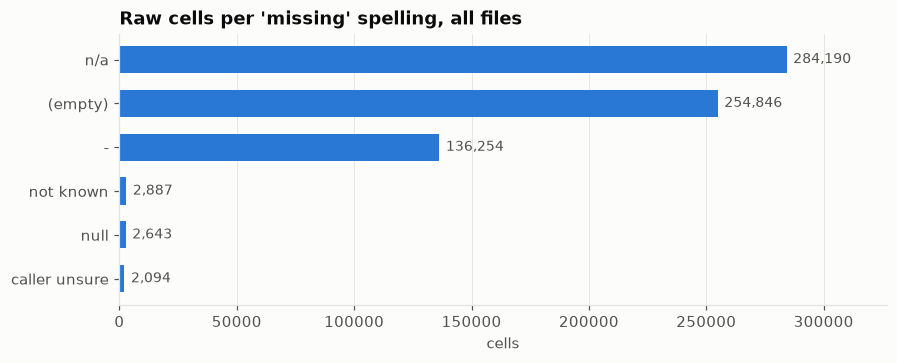

Other placeholder-like values found: {'report_history_train': 0, 'report_history_eval': 0, 'repair_logs_train': 0, 'repair_logs_eval': 0, 'statement_sentences': 0, 'open_defect_reports': 0, 'report_documents': 0, 'street_works_register': 0}


In [5]:
tok = {}
for k, v in verbatim.items():
    vals = v.apply(lambda s: s.str.strip().str.lower()).stack()
    tok[k] = vals[vals.isin(NULL_TOKENS)].replace({"": "(empty)"}).value_counts()
tok = pd.DataFrame(tok).fillna(0).astype(int).T
display(tok)

fig, ax = plt.subplots(figsize=(9, 3.2))
tot = tok.sum().sort_values(ascending=False)
hbar(ax, tot)
ax.set_title("Raw cells per 'missing' spelling, all files"); ax.set_xlabel("cells")
save(fig, "05_null_tokens")

# Are there other placeholder-like strings we might have missed?
suspicious = re.compile(r"^(unknown|none given|na|nan|\?+|tbc|n\.a\.)$", re.I)
extra = {k: int(v.stack().str.strip().str.match(suspicious).sum()) for k, v in verbatim.items()}
print("Other placeholder-like values found:", extra)

There are six spellings of "missing" and no others. `"None"` is deliberately **not** a null token. In `linked_defect_type` it means "No linked defect", and in `traffic_management` it means *no traffic management*. Both are real answers.

### 5.2 Exact duplicates and repeated identifiers

In [6]:
def dup_report():
    rows = []
    for k, v in verbatim.items():
        idcol = {"statement_sentences": "sentence_id", "report_documents": "document_id",
                 "street_works_register": "permit_reference"}.get(k, "report_reference")
        dedup = v.drop_duplicates()
        rows.append({"file": k, "exact duplicate rows": int(v.duplicated().sum()),
                     "id column": idcol,
                     "ids repeated after dedup (raw notation)": int(dedup[idcol].duplicated().sum())})
    return pd.DataFrame(rows).set_index("file")
display(dup_report())

,exact duplicate rows,id column,ids repeated after dedup (raw notation)
file,,,
report_history_train,369,report_reference,1569
report_history_eval,93,report_reference,409
repair_logs_train,303,report_reference,0
repair_logs_eval,74,report_reference,0
statement_sentences,445,sentence_id,0
open_defect_reports,2,report_reference,3
report_documents,2,document_id,0
street_works_register,1,permit_reference,0


* In the **history**, a repeated reference after deduplication is expected because those rows are revisions (§5.5).
* In the **repair logs**, the spec says "no report appears twice", yet references in *different notations* can still point to the same report. This is checked after canonicalisation in §6.
* For **sentences, documents and permits**, after exact duplicates are removed the IDs must be unique.

### 5.3 Three notations for one report reference

In [7]:
def notation(s):
    return np.select([s.str.match(r"^SC\d{7}$", na=False), s.str.match(r"^SC-\d+$", na=False),
                      s.str.match(r"^\d+$", na=False)], ["SC0000000", "SC-n", "bare n"], "other")

nt = pd.concat([pd.DataFrame({"channel": raw[k]["report_channel"], "notation": notation(raw[k]["report_reference"])})
                for k in ["report_history_train", "repair_logs_train", "statement_sentences"]], ignore_index=True)
display(pd.crosstab(nt["channel"], nt["notation"], margins=True))

notation,SC-n,SC0000000,bare n,All
channel,,,,
Contact centre,0,0,17966,17966
StreetCare app,36343,0,0,36343
Website,0,41185,0,41185
All,36343,41185,17966,95494


Each channel uses exactly one notation: Website → `SC0050118`, app → `SC-50118`, contact centre → `50118`. No reference is in any other form, so a single regex covers them all, and the canonical form is `SC` + the number zero-padded to 7 digits.

### 5.4 One category, many spellings

In [8]:
cat_cols = ["defect_type", "linked_defect_type", "street_category", "district", "reporter_type",
            "water_location", "overhang_location", "lighting_fault", "location_fixed",
            "photograph_attached", "review_outcome", "reported_again", "repeat_cause"]
h = raw["report_history_train"]
spell = pd.DataFrame({
    "raw spellings": [h[c].nunique() for c in cat_cols],
    "after case-fold": [h[c].str.lower().nunique() for c in cat_cols],
}, index=cat_cols)
r_ = raw["repair_logs_train"]; s_ = raw["statement_sentences"]
for c, df in [("repair_method", r_), ("traffic_management", r_), ("completion_code", r_),
              ("sentence_type", s_), ("document_type", s_)]:
    spell.loc[c] = [df[c].nunique(), df[c].str.lower().nunique()]
display(spell)
print("defect_type raw spellings:", sorted(h["defect_type"].dropna().str.lower().unique()))

,raw spellings,after case-fold
defect_type,40,15
linked_defect_type,48,18
street_category,16,6
district,12,4
reporter_type,15,5
water_location,14,5
overhang_location,14,5
lighting_fault,24,9
location_fixed,18,8
photograph_attached,18,8


defect_type raw spellings: ['carriageway', 'cw', 'dr', 'drainage', 'flooding or blocked drain', 'footway', 'fw', 'overhanging tree or hedge', 'pavement defect', 'pothole or road surface', 'sl', 'street light fault', 'street lighting', 'vegetation', 'vg']


Lower-casing alone removes most of the variation, which is the *padding and case* defect. What remains is *channel vocabulary*, where the same defect type is written three ways (`Footway` / `Pavement defect` / `FW`) and needs an explicit mapping. The spec requires that any spelling the mapping does not list is **refused, not guessed**, and §6 enforces this.

### 5.5 Units: one reading, several notations

In [9]:
READ_COLS = ["defect_depth_mm", "defect_width_mm", "water_depth_mm", "water_reach_m", "clear_height_m",
             "column_lean_degrees", "column_height_m", "planned_crew_hours"]
def unit_of(s):
    u = s.dropna().str.extract(r"^-?\d+(?:\.\d+)?\s*([a-z]*)$", flags=re.I)[0].fillna("?unparsed")
    return u.replace({"": "(bare number)"})
units = pd.DataFrame({c: unit_of(h[c]).value_counts() for c in READ_COLS}).fillna(0).astype(int).T
display(units)
lg = raw["repair_logs_train"]
display(pd.DataFrame({c: unit_of(lg[c]).value_counts() for c in ["planned_crew_hours", "actual_crew_hours"]}).fillna(0).astype(int).T)
print("Unit notation by channel (history depth):")
display(pd.crosstab(h["report_channel"], unit_of(h["defect_depth_mm"])))

,(bare number),cm,deg,ft,hr,hrs,in,m,min
defect_depth_mm,6894,6622,0,0,0,0,3050,0,0
defect_width_mm,6857,6520,0,0,0,0,2947,0,0
water_depth_mm,2844,2525,0,0,0,0,1298,0,0
water_reach_m,2066,0,0,911,0,0,0,1872,0
clear_height_m,2478,0,0,1058,0,0,0,1855,0
column_lean_degrees,300,0,273,0,0,0,0,0,0
column_height_m,2407,0,0,1347,0,0,0,2130,0
planned_crew_hours,13663,0,0,0,639,5859,0,0,12258


,(bare number),min,hrs,hr
planned_crew_hours,10944,9758,4537,614
actual_crew_hours,10965,9757,5062,98


Unit notation by channel (history depth):


,(bare number),cm,in
report_channel,,,
Contact centre,0,0,3050
StreetCare app,0,6622,0
Website,6894,0,0


Each unit notation maps cleanly to a multiplier: `cm` ×10 and `in` ×25.4 → mm; `ft` ×0.3048 → m; `min` ÷60 → hours; `deg`, `m`, `hr`/`hrs` and a bare number are already in the reading's unit. Nothing is left unparsed. The crosstab shows that each channel has its own unit habit for a given reading (for depth: Website a bare number in mm, app centimetres, contact centre inches). Because the habit differs from one reading to the next (a bare column height is in metres, not millimetres), the unit must still be read from each value's own suffix and never inferred from the channel.

### 5.6 Revisions of the same report

In [10]:
hh = raw["report_history_train"].drop_duplicates().copy()
hh["ref"] = hh["report_reference"].str.extract(r"(\d+)$")[0].astype(int)
hh["rev"] = hh["revision_number"].astype(int)
per = hh.groupby("ref")["rev"].agg(["count", "max"])
display(per["count"].value_counts().rename("reports with N rows").to_frame())
# Are the revisions contiguous in the file, or scattered?
pos = hh.reset_index().groupby("ref")["index"].agg(["min", "max", "count"])
multi = pos[pos["count"] > 1]
print(f"{len(multi):,} reports have >1 revision; median distance between their first and last row: "
      f"{int((multi['max'] - multi['min']).median()):,} rows -> revisions are scattered through the file.")
# Does the latest revision always carry the answer?
latest = hh.loc[hh.groupby("ref")["rev"].idxmax()]
print("Latest revisions with no reported_again (must be dropped, never back-filled):",
      int(latest["reported_again"].isna().sum()))

,reports with N rows
count,
1,29371
2,1289
3,140


1,429 reports have >1 revision; median distance between their first and last row: 10,793 rows -> revisions are scattered through the file.
Latest revisions with no reported_again (must be dropped, never back-filled): 231


Revisions are spread throughout the file, so a "keep last row" deduplication would be wrong. The rule is to keep the row with the highest `revision_number`, wherever it sits. If the latest revision has no answer, the report is **dropped**, and an earlier revision never stands in for it.

### 5.7 Impossible readings and impossible answers

In [11]:
def num(s):
    return pd.to_numeric(s.str.extract(r"^(-?\d+(?:\.\d+)?)")[0], errors="coerce")
checks = {
    "negative defect depth": (h, "defect_depth_mm", lambda x: x < 0),
    "zero defect width": (h, "defect_width_mm", lambda x: x == 0),
    "negative water depth": (h, "water_depth_mm", lambda x: x < 0),
    "zero clear height": (h, "clear_height_m", lambda x: x == 0),
    "zero column height": (h, "column_height_m", lambda x: x == 0),
    "lean > 90 degrees": (h, "column_lean_degrees", lambda x: x > 90),
    "planned crew hours = 0": (h, "planned_crew_hours", lambda x: x == 0),
    "negative previous reports": (h, "previous_reports_at_location", lambda x: x < 0),
    "crew size = 0 (logs)": (lg, "crew_size", lambda x: x == 0),
    "negative actual crew hours (logs)": (lg, "actual_crew_hours", lambda x: x < 0),
}
display(pd.Series({k: int(f(num(df[c])).sum()) for k, (df, c, f) in checks.items()},
                  name="raw rows (train files)").to_frame())

,raw rows (train files)
negative defect depth,41
zero defect width,31
negative water depth,21
zero clear height,11
zero column height,10
lean > 90 degrees,3
planned crew hours = 0,43
negative previous reports,49
crew size = 0 (logs),44
negative actual crew hours (logs),46


These values cannot be real. The spec says to **blank** them (make them missing) rather than correct them, because a guess would pass or fail the wrong requirement. The exception is a negative `actual_crew_hours`, which is the target itself, so that row is removed from training. *Assumption:* the spec's `LEAN_MAXIMUM` is in `config.py`, so we use 90° here (a column cannot lean more than flat).

### 5.8 Free-text defects in sentences and documents

In [12]:
st = verbatim["statement_sentences"]["sentence_text"]
dt = verbatim["report_documents"]["document_text"]
def text_defects(t):
    return pd.Series({
        "markup tags (<span>, <br/>)": t.str.contains(r"<[^>]+>").sum(),
        "HTML entities (&nbsp; &#45; ...)": t.str.contains(r"&[#a-z0-9]+;", case=False).sum(),
        "no-break space U+00A0": t.str.contains(" ").sum(),
        "leading/trailing padding": (t != t.str.strip()).sum(),
        "runs of 2+ spaces": t.str.contains(r"\s{2,}").sum(),
        "written wholly in CAPS": (t.str.contains(r"[A-Za-z]") & ~t.str.contains(r"[a-z]")).sum(),
    })
display(pd.DataFrame({"statement_sentences": text_defects(st), "report_documents": text_defects(dt)}))
print(verbatim["statement_sentences"].loc[st.str.contains("<|&"), "sentence_text"].head(4).to_string())

,statement_sentences,report_documents
"markup tags (<span>, <br/>)",3604,19
HTML entities (&nbsp; &#45; ...),1786,3
no-break space U+00A0,1116,5
leading/trailing padding,1101,4
runs of 2+ spaces,374,4
written wholly in CAPS,434,0


3          <p>The earlier repair on Albert <br/>Street is breaking up already.</span>
10    Rain&nbsp;water collects in the dip by the driveway on Foundry Lane, to be h...
14           <span>This location on Northgate has been repaired several times.</span>
15                                      <span>Dog walkers use <b>Northgate a lot.</p>


All of these defects can be repaired deterministically: strip tags, unescape entities, collapse whitespace (including U+00A0), and lower-case a sentence written wholly in capitals, since that is the only way it can be restored. `sentence_length_characters` was measured on the *raw* text, so it is stale after cleaning and has to be recomputed (§9.1).

## 6. EDA-grade cleaning

These are the canonical mappings, rebuilt from the spec's wording and from every spelling observed in §5. Each mapping is **closed**: an unlisted spelling raises an error naming the column and the value, in line with the spec's "refused, never guessed" rule. Unit conversion uses `Decimal` and rounds half-up once, at the reading's precision (`4.5 cm → 45 mm`, `1.75 in → 44 mm`, `4 ft → 1.2 m`, `45 min → 0.8 h`).

In [13]:
def build(groups):
    return {alias: canon for canon, aliases in groups.items() for alias in [canon.lower(), *aliases]}

DEFECT = build({"Carriageway": ["cw", "pothole or road surface"], "Footway": ["fw", "pavement defect"],
                "Drainage": ["dr", "flooding or blocked drain"], "Vegetation": ["vg", "overhanging tree or hedge"],
                "Street lighting": ["sl", "street light fault"]})
LINKED = {**DEFECT, **build({"No linked defect": ["none", "nil"]})}
MAPS = {
    "defect_type": DEFECT, "linked_defect_type": LINKED,
    "street_category": build({"Traffic sensitive": ["ts", "main route"], "Local road": ["lr", "residential street"]}),
    "district": build({"Town Centre": [], "North": [], "South": [], "Villages": []}),
    "reporter_type": build({"Resident": [], "Business": [], "Councillor": [], "Bus operator": [], "School": []}),
    "water_location": build({"Carriageway": ["road"], "Footway": ["pavement", "path"]}),
    "overhang_location": build({"Carriageway": ["road"], "Footway": ["pavement", "path"]}),
    "lighting_fault": build({"Lamp out": ["out", "light not working"], "Day burning": ["day", "light on in daytime"],
                             "Leaning column": ["lean", "column leaning"]}),
    "review_outcome": build({"Repaired as reported": ["repaired", "rep"],
                             "Repaired after inspection": ["repaired - inspected", "rep-ins"],
                             "Repaired after coordination": ["repaired - coordinated", "rep-crd"],
                             "Closed after inspection": ["closed - inspected", "cls-ins"]}),
    "repeat_cause": build({"Repair failed": ["failed"], "Defect returned nearby": ["nearby", "new defect nearby"],
                           "Regrowth": ["grown back"], "Blocked again": ["reblocked"],
                           "Lamp failed again": ["failed again", "refail"],
                           "Worsened after inspection": ["worse", "got worse"]}),
    "repair_method": build({"Patch repair": ["patch"], "Permanent reinstatement": ["perm", "permanent"],
                            "Slab relay": ["relay", "relay slabs"], "Gully cleanse": ["gully", "cleanse gully"],
                            "Drain repair": ["drain", "repair drain"], "Cut back": ["cut"],
                            "Lamp replacement": ["lamp", "replace lamp"],
                            "Photocell replacement": ["pecu", "replace photocell"],
                            "Column replacement": ["column", "replace column"]}),
    "traffic_management": build({"None": ["no traffic management"], "Signs only": ["signs"],
                                 "Lane closure": ["lane", "lane closed"],
                                 "Road closure": ["closed", "road closed"]}),
    "completion_code": build({"Completed": ["comp", "done"],
                              "Completed with overrun": ["comp-ovr", "done - overran"],
                              "Completed after return visit": ["comp-rtn", "done - second visit"]}),
    "sentence_type": build({"Measurement": ["measurements"], "Location": ["where"], "Photograph": ["photo"],
                            "Hazard": ["danger"], "Incident": ["accident"],
                            "Traffic and use": ["traffic & use", "traffic-and-use", "traffic"],
                            "Previous reports": ["previous report", "previous-reports"],
                            "Weather and water": ["weather & water", "weather-and-water", "weather"],
                            "Background": ["context", "general"]}),
    "document_type": build({"Resident description": [], "Call note": [], "Photo note": [], "Inspection note": []}),
    "permit_status": build({"Live": [], "Cancelled": []}),
    "works_location": build({"Carriageway": [], "Footway": []}),
}
BOOL = build({"Yes": ["true", "y", "1"], "No": ["false", "n", "0"]})
for c in ["location_fixed", "photograph_attached", "on_highway_land", "column_number_given", "reported_again"]:
    MAPS[c] = BOOL

# reading -> (unit multipliers, step).  A bare number is already in the reading's unit.
MM = ({"": 1, "mm": 1, "cm": 10, "in": Decimal("25.4")}, Decimal("1"))
M = ({"": 1, "m": 1, "ft": Decimal("0.3048")}, Decimal("0.1"))
DEG = ({"": 1, "deg": 1}, Decimal("0.1"))
HRS = ({"": 1, "hr": 1, "hrs": 1, "min": 1 / Decimal(60)}, Decimal("0.1"))
READINGS = {"defect_depth_mm": MM, "defect_width_mm": MM, "water_depth_mm": MM, "water_reach_m": M,
            "clear_height_m": M, "column_height_m": M, "column_lean_degrees": DEG,
            "planned_crew_hours": HRS, "actual_crew_hours": HRS}
COUNTS = ["revision_number", "previous_reports_at_location", "live_street_works_on_street",
          "conflicting_street_works", "crew_size", "sentence_number", "supporting_document_count"]
# smallest / largest value that can be real (EDA assumptions mirroring the spec's examples)
MINIMUM = {"defect_depth_mm": 0, "defect_width_mm": 1, "water_depth_mm": 0, "clear_height_m": 0.1,
           "column_height_m": 0.1, "column_lean_degrees": 0, "planned_crew_hours": 0.1,
           "previous_reports_at_location": 0, "crew_size": 1, "actual_crew_hours": 0}
MAXIMUM = {"column_lean_degrees": 90}

def canon_ref(s):
    n = s.str.extract(r"^(?:SC-?)?(\d+)$")[0]
    bad = s.notna() & n.isna()
    if bad.any(): raise ValueError(f"report_reference: unreadable {s[bad].unique()[:5]}")
    return ("SC" + n.str.zfill(7)).where(s.notna())

def map_col(s, mapping, col):
    low = s.str.lower()
    out = low.map(mapping)
    bad = s.notna() & out.isna()
    if bad.any(): raise ValueError(f"{col}: unlisted spelling(s) {sorted(s[bad].unique())[:8]}")
    return out

def read_value(v, units, step):
    if pd.isna(v): return np.nan
    m = re.fullmatch(r"(-?\d+(?:\.\d+)?)\s*([a-z]*)", v, flags=re.I)
    if not m or m.group(2).lower() not in units: raise ValueError(f"unreadable reading {v!r}")
    x = Decimal(m.group(1)) * Decimal(units[m.group(2).lower()])
    return float(x.quantize(step, rounding=ROUND_HALF_UP))

def plain_text(s):
    s = s.str.replace(r"<[^>]+>", " ", regex=True).map(lambda t: html.unescape(t) if isinstance(t, str) else t)
    return s.str.replace(r"[\s ]+", " ", regex=True).str.strip()

def clean(df, latest_revision=False, target=None):
    df = df.drop_duplicates().reset_index(drop=True).copy()
    if "report_reference" in df: df["report_reference"] = canon_ref(df["report_reference"])
    if "street_name" in df: df["street_name"] = df["street_name"].str.title().str.replace(r"\s+", " ", regex=True)
    for c, mp in MAPS.items():
        if c in df: df[c] = map_col(df[c], mp, c)
    for c, (units, step) in READINGS.items():
        if c in df: df[c] = df[c].map(lambda v: read_value(v, units, step))
    for c in COUNTS:
        if c in df: df[c] = pd.to_numeric(df[c]).astype("Int64")
    for c, lo in MINIMUM.items():
        if c in df: df.loc[df[c] < lo, c] = np.nan
    for c, hi in MAXIMUM.items():
        if c in df: df.loc[df[c] > hi, c] = np.nan
    if latest_revision:
        df = df.loc[df.groupby("report_reference")["revision_number"].idxmax()].sort_index().reset_index(drop=True)
    if target is not None:
        df = df[df[target].notna()].reset_index(drop=True)
    return df

H_tr = clean(raw["report_history_train"], latest_revision=True, target="reported_again")
H_ev = clean(raw["report_history_eval"], latest_revision=True, target="reported_again")
L_tr = clean(raw["repair_logs_train"], target="actual_crew_hours")
L_ev = clean(raw["repair_logs_eval"], target="actual_crew_hours")

S = raw["statement_sentences"].drop_duplicates().reset_index(drop=True).copy()
S["report_reference"] = canon_ref(S["report_reference"])
S["document_type"] = map_col(S["document_type"], MAPS["document_type"], "document_type")
S["sentence_type"] = map_col(S["sentence_type"], MAPS["sentence_type"], "sentence_type")
S["sentence_text"] = plain_text(S["sentence_text"])
caps = S["sentence_text"].str.contains(r"[A-Za-z]", na=False) & ~S["sentence_text"].str.contains(r"[a-z]", na=False)
S.loc[caps, "sentence_text"] = S.loc[caps, "sentence_text"].str.lower()
S["raw_length"] = pd.to_numeric(S["sentence_length_characters"])
S["sentence_length_characters"] = S["sentence_text"].str.len()
S["words"] = S["sentence_text"].str.split().str.len()
MIN_WORDS = 3  # assumption standing in for config.MINIMUM_SENTENCE_WORDS
S_clean = S[S["sentence_type"].notna() & (S["words"] >= MIN_WORDS)].reset_index(drop=True)

OPEN = clean(raw["open_defect_reports"], latest_revision=True)
DOCS = raw["report_documents"].drop_duplicates().reset_index(drop=True).copy()
DOCS["report_reference"] = canon_ref(DOCS["report_reference"])
DOCS["document_type"] = map_col(DOCS["document_type"], MAPS["document_type"], "document_type")
DOCS["document_text"] = plain_text(DOCS["document_text"])
REG = clean(raw["street_works_register"])

summary = pd.DataFrame({
    "raw rows": [len(raw[k]) for k in ["report_history_train", "report_history_eval", "repair_logs_train",
                                        "repair_logs_eval", "statement_sentences", "open_defect_reports",
                                        "report_documents", "street_works_register"]],
    "clean rows": [len(H_tr), len(H_ev), len(L_tr), len(L_ev), len(S_clean), len(OPEN), len(DOCS), len(REG)],
}, index=["history train", "history eval", "repair logs train", "repair logs eval", "sentences",
          "open reports", "report documents", "register"])
summary["kept %"] = (100 * summary["clean rows"] / summary["raw rows"]).round(1)
display(summary)
print("Repair logs: report repeated after canonicalisation ->", int(L_tr["report_reference"].duplicated().sum()),
      "(train),", int(L_ev["report_reference"].duplicated().sum()), "(eval)")
print("Sentences: repeated sentence_id after dedup ->", int(S["sentence_id"].duplicated().sum()))
print("Register: permits", len(REG), "| live", int((REG["permit_status"] == "Live").sum()),
      "| open reports", len(OPEN), "| documents", len(DOCS))

,raw rows,clean rows,kept %
history train,32738,30569,93.4
history eval,8202,7648,93.2
repair logs train,26095,25537,97.9
repair logs eval,6476,6337,97.9
sentences,36661,35717,97.4
open reports,45,40,88.9
report documents,62,60,96.8
register,29,28,96.6


Repair logs: report repeated after canonicalisation -> 0 (train), 0 (eval)
Sentences: repeated sentence_id after dedup -> 0
Register: permits 28 | live 23 | open reports 40 | documents 60


The cleaned live files match the counts the specification states: **40 open reports**, **60 documents** and **28 permits, of which 23 are live**. That is a useful independent check that the mappings and the dedup and latest-revision rules are right.

### 6.1 What cleaning removed

The chart shows, for each training extract, where the raw rows went.

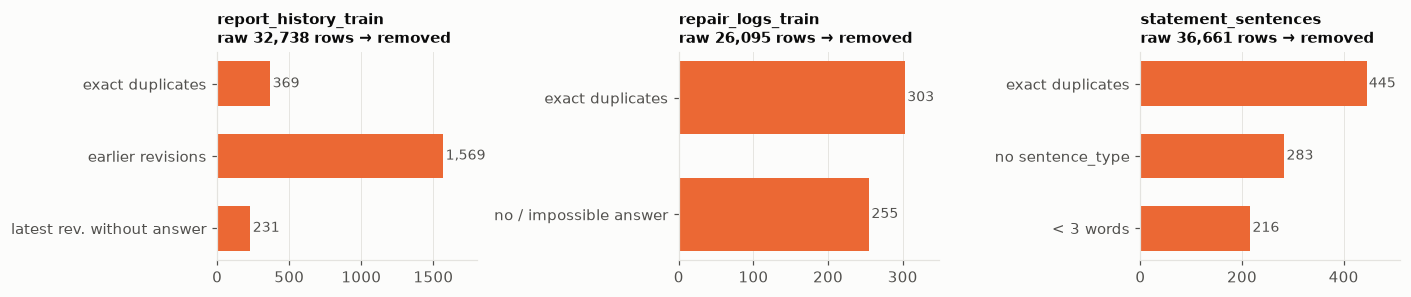

In [14]:
def funnel_history(rawdf):
    d = rawdf.drop_duplicates(); r = canon_ref(d["report_reference"])
    n_latest = r.nunique()
    return {"raw": len(rawdf), "exact duplicates": len(rawdf) - len(d),
            "earlier revisions": len(d) - n_latest, "latest rev. without answer": n_latest - len(H_tr)}
def funnel_logs(rawdf):
    d = rawdf.drop_duplicates()
    return {"raw": len(rawdf), "exact duplicates": len(rawdf) - len(d), "no / impossible answer": len(d) - len(L_tr)}
def funnel_sent():
    return {"raw": len(raw["statement_sentences"]), "exact duplicates": len(raw["statement_sentences"]) - len(S),
            "no sentence_type": int(S["sentence_type"].isna().sum()),
            f"< {MIN_WORDS} words": int((S["sentence_type"].notna() & (S["words"] < MIN_WORDS)).sum())}
fun = {"report_history_train": funnel_history(raw["report_history_train"]),
       "repair_logs_train": funnel_logs(raw["repair_logs_train"]), "statement_sentences": funnel_sent()}
fig, axes = plt.subplots(1, 3, figsize=(13, 2.8))
for ax, (k, f) in zip(axes, fun.items()):
    hbar(ax, pd.Series({kk: vv for kk, vv in f.items() if kk != "raw"}), PALETTE[1])
    ax.set_title(f"{k}\nraw {f['raw']:,} rows → removed", fontsize=10)
fig.tight_layout(); save(fig, "06_cleaning_funnel")

## 7. Report history — the repeat-likelihood data

**Unit of analysis:** one decided report at its latest revision. **Target:** `reported_again` (Yes/No). The model is a logistic regression, scored on the eval file by ROC AUC.

### 7.1 Target balance

In [15]:
y_tr = (H_tr["reported_again"] == "Yes"); y_ev = (H_ev["reported_again"] == "Yes")
print(f"train: {len(H_tr):,} reports, repeat rate {y_tr.mean():.1%} | eval: {len(H_ev):,} reports, repeat rate {y_ev.mean():.1%}")

train: 30,569 reports, repeat rate 20.2% | eval: 7,648 reports, repeat rate 20.3%


The classes are imbalanced, so accuracy would be a misleading metric. ROC AUC, which the spec uses, measures ranking and is not affected by the class balance. The model's predicted probabilities should also be *calibrated*: the spec requires the mean held-out score to sit close to the observed rate.

### 7.2 Structural missingness: what each defect type answers

Each defect standard asks for different answers, so most blanks are **by design**. The heat-map shows the share of reports of each type that answer each column.

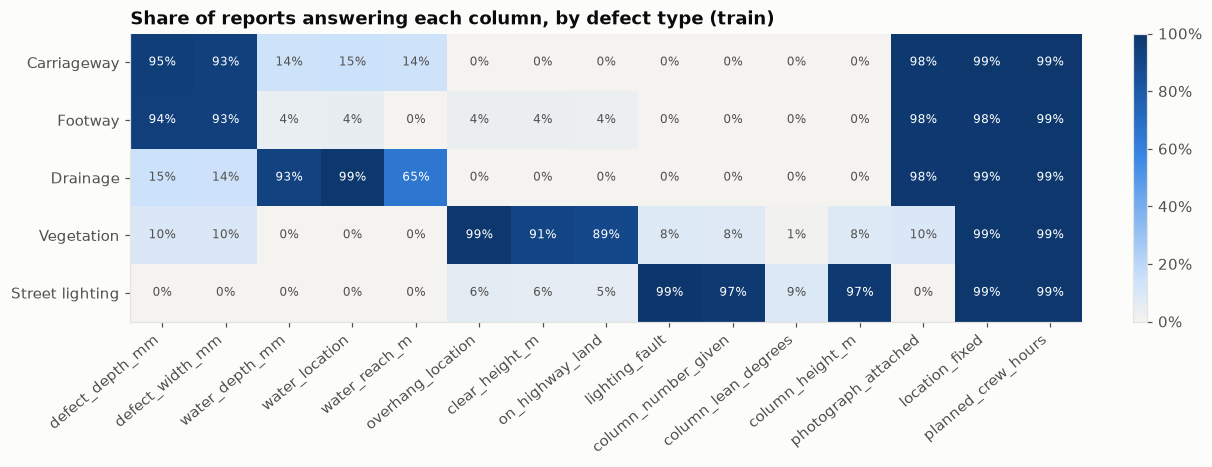

In [16]:
ans_cols = ["defect_depth_mm", "defect_width_mm", "water_depth_mm", "water_location", "water_reach_m",
            "overhang_location", "clear_height_m", "on_highway_land", "lighting_fault",
            "column_number_given", "column_lean_degrees", "column_height_m", "photograph_attached",
            "location_fixed", "planned_crew_hours"]
fill = H_tr.groupby("defect_type")[ans_cols].apply(lambda g: g.notna().mean()).reindex(DEFECT_ORDER)
fig, ax = plt.subplots(figsize=(12, 3.4))
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("seq", ["#f4f3ef"] + SEQ)
im = ax.imshow(fill.values, cmap=cmap, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(ans_cols)), ans_cols, rotation=40, ha="right"); ax.set_yticks(range(5), fill.index)
for i in range(fill.shape[0]):
    for j in range(fill.shape[1]):
        v = fill.values[i, j]; ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8,
                                       color="white" if v > 0.6 else INK2)
ax.grid(False); ax.set_title("Share of reports answering each column, by defect type (train)")
fig.colorbar(im, ax=ax, fraction=0.02, format=lambda x, _: f"{x:.0%}")
save(fig, "07_structural_missingness")

Each type's columns appear as a block. Within a block, answers are filled in ~85–95% of cases, and the remaining blanks are the genuine **Not documented** cases. Outside a block a few cells are non-zero; these are reports whose **linked** type asks for that column. Because a column is blank whenever the defect type doesn't ask for it, a plain median imputation would invent false measurements. Instead, the saved preprocessing must handle "not applicable" (for example, impute together with a missing-indicator, or use type-specific features).

### 7.3 Repeat rate by category

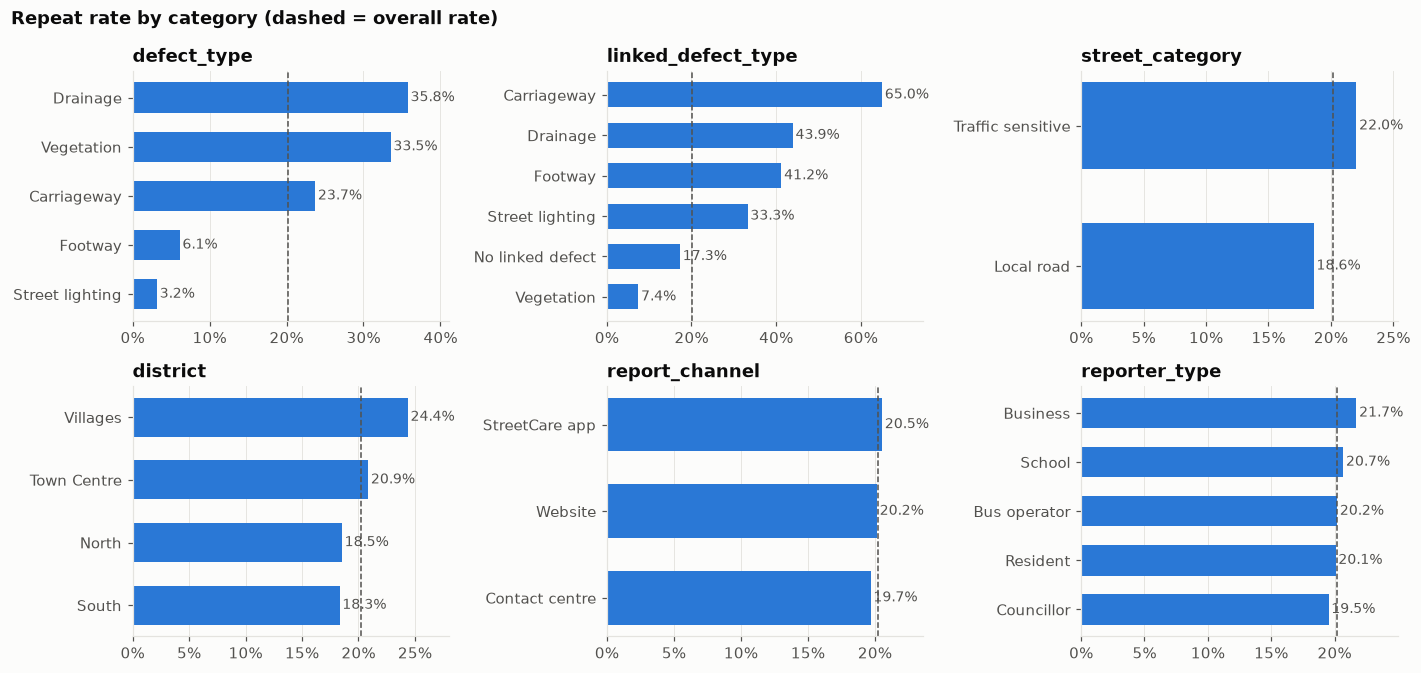

In [17]:
def rate_table(df, col):
    g = df.groupby(col)["reported_again"].agg(n="size", repeat_rate=lambda s: (s == "Yes").mean())
    return g.sort_values("repeat_rate", ascending=False)

fig, axes = plt.subplots(2, 3, figsize=(13, 6.2))
for ax, col in zip(axes.flat, ["defect_type", "linked_defect_type", "street_category", "district",
                               "report_channel", "reporter_type"]):
    t = rate_table(H_tr, col)
    hbar(ax, t["repeat_rate"], PALETTE[0], fmt="{:.1%}")
    ax.set_title(col); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.axvline(y_tr.mean(), color=INK2, lw=1, ls="--")
fig.suptitle("Repeat rate by category (dashed = overall rate)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "07_repeat_by_category")

### 7.4 Repeat rate vs history at the location and street works

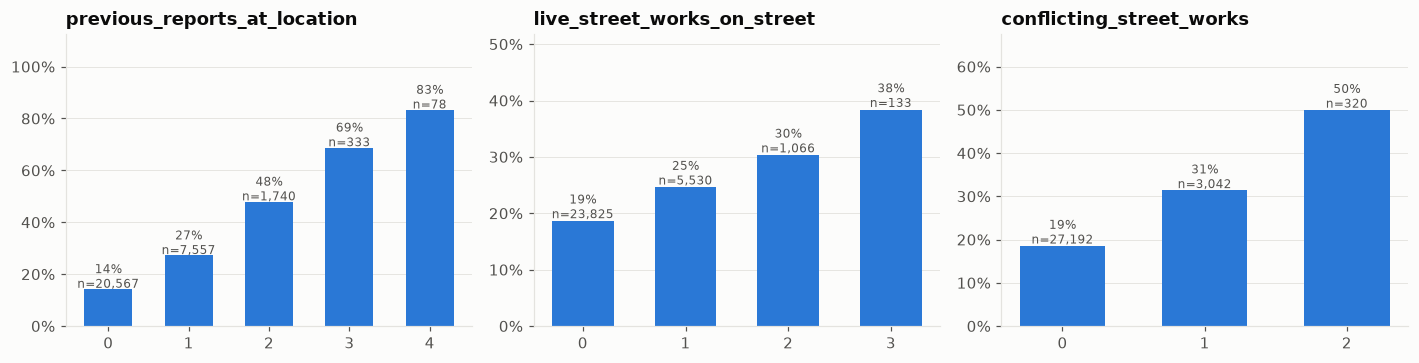

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col in zip(axes, ["previous_reports_at_location", "live_street_works_on_street", "conflicting_street_works"]):
    t = H_tr.groupby(col)["reported_again"].agg(n="size", rate=lambda s: (s == "Yes").mean())
    t = t[t["n"] >= 30]
    ax.bar(t.index.astype(str), t["rate"], color=PALETTE[0], width=0.6)
    for i, (r, n) in enumerate(zip(t["rate"], t["n"])):
        ax.text(i, r + 0.005, f"{r:.0%}\nn={n:,}", ha="center", fontsize=8, color=INK2)
    ax.set_title(col); ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.grid(axis="x", visible=False)
    ax.set_ylim(0, t["rate"].max() * 1.35)
fig.tight_layout(); save(fig, "07_repeat_vs_counts")

The spec's monotonicity requirements say that *one more conflicting live permit must raise the score* and *turning a requirement from Met to Not met must raise it*. These charts show whether the raw data supports that direction. Groups with fewer than 30 reports are hidden so that small samples don't produce noisy rates.

### 7.5 Readings by defect type (cleaned units)

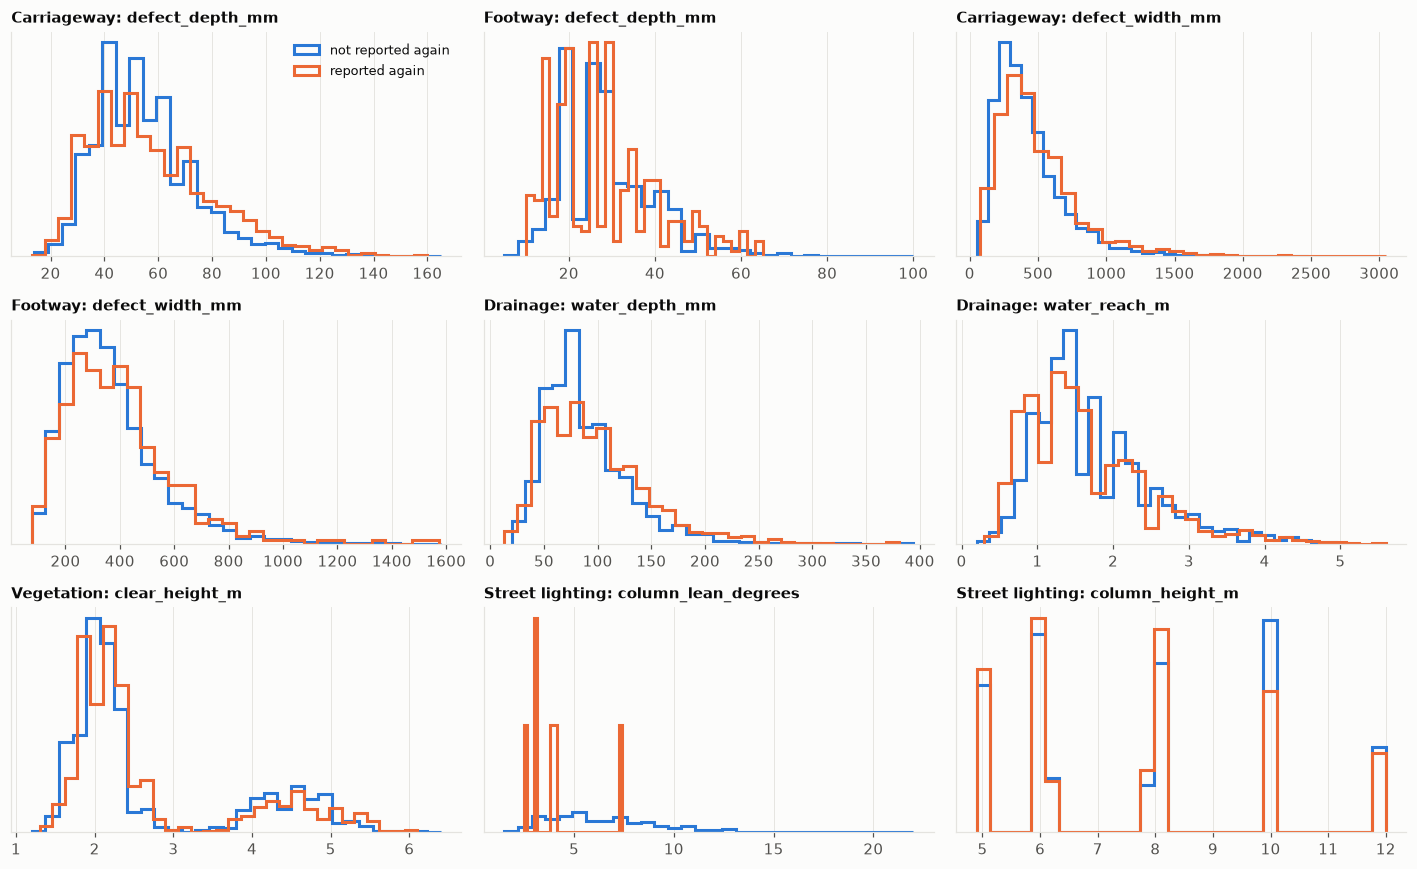

,defect_depth_mm,defect_width_mm,water_depth_mm,water_reach_m,clear_height_m,column_lean_degrees,column_height_m,planned_crew_hours
defect_type,,,,,,,,
Carriageway,51.0,381.0,80.0,1.5,NaN,NaN,NaN,3.0
Footway,27.0,330.0,85.0,NaN,2.0,NaN,NaN,2.0
Drainage,45.0,370.0,80.0,1.5,NaN,NaN,NaN,2.0
Vegetation,26.0,327.5,NaN,NaN,2.2,5.7,6.0,1.5
Street lighting,NaN,NaN,NaN,NaN,2.1,5.9,8.0,1.0


In [19]:
read_pairs = [("Carriageway", "defect_depth_mm"), ("Footway", "defect_depth_mm"),
              ("Carriageway", "defect_width_mm"), ("Footway", "defect_width_mm"),
              ("Drainage", "water_depth_mm"), ("Drainage", "water_reach_m"),
              ("Vegetation", "clear_height_m"), ("Street lighting", "column_lean_degrees"),
              ("Street lighting", "column_height_m")]
fig, axes = plt.subplots(3, 3, figsize=(13, 8))
for ax, (t, c) in zip(axes.flat, read_pairs):
    sub = H_tr[H_tr["defect_type"] == t]
    for lab, col, ls in [("not reported again", PALETTE[0], "-"), ("reported again", PALETTE[1], "-")]:
        v = sub.loc[(sub["reported_again"] == "Yes") == (lab == "reported again"), c].dropna()
        if len(v): ax.hist(v, bins=30, histtype="step", lw=2, color=col, density=True, label=lab)
    ax.set_title(f"{t}: {c}", fontsize=10); ax.set_yticks([])
axes.flat[0].legend(fontsize=8.5)
fig.tight_layout(); save(fig, "07_readings_by_target")
display(H_tr.groupby("defect_type")[["defect_depth_mm", "defect_width_mm", "water_depth_mm", "water_reach_m",
                                     "clear_height_m", "column_lean_degrees", "column_height_m",
                                     "planned_crew_hours"]].median().reindex(DEFECT_ORDER))

Once converted, every reading sits on one scale, and before conversion it would have been in mixed units. Comparing the Carriageway and Footway depths shows why the **same requirement wording carries different figures** in the two standards (§11): the distributions differ.

### 7.6 Review outcome and repeat cause (post-outcome, analysis only)

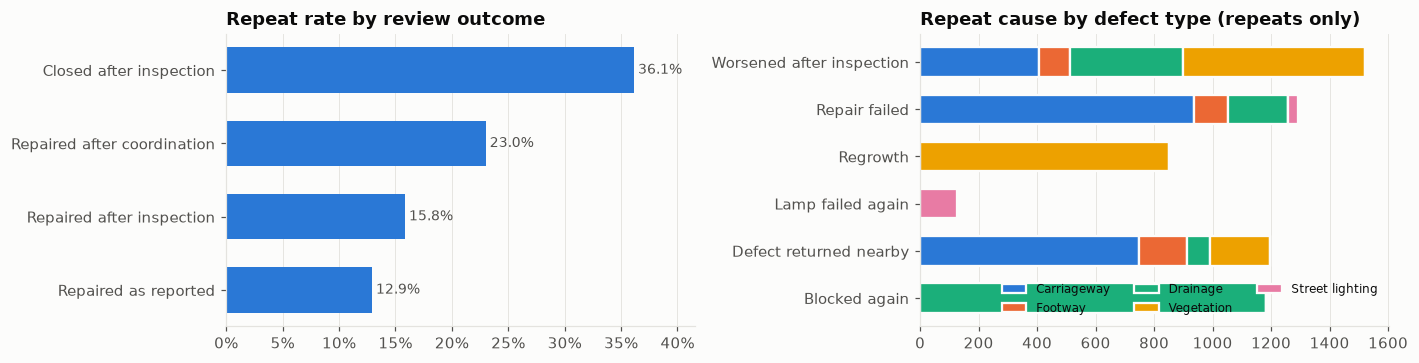

repeat_cause filled when reported_again=No: 0 | filled when Yes: 100%


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
t = rate_table(H_tr, "review_outcome")
hbar(axes[0], t["repeat_rate"], PALETTE[0], fmt="{:.1%}")
axes[0].set_title("Repeat rate by review outcome"); axes[0].xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
rc = pd.crosstab(H_tr["repeat_cause"], H_tr["defect_type"]).reindex(columns=DEFECT_ORDER)
left = np.zeros(len(rc))
for i, dtp in enumerate(DEFECT_ORDER):
    axes[1].barh(rc.index, rc[dtp], left=left, color=DEFECT_COLOR[dtp], label=dtp, height=0.62,
                 edgecolor=SURFACE, linewidth=1.5)
    left += rc[dtp].values
axes[1].legend(fontsize=8, ncol=3, loc="lower right"); axes[1].set_title("Repeat cause by defect type (repeats only)")
axes[1].grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "07_outcome_cause")
print("repeat_cause filled when reported_again=No:", int(H_tr.loc[~y_tr, "repeat_cause"].notna().sum()),
      "| filled when Yes:", f"{H_tr.loc[y_tr, 'repeat_cause'].notna().mean():.0%}")

`repeat_cause` is filled **only** when the defect came back, so it is a perfect proxy for the target and must be excluded from features. Each cause belongs to a type (Regrowth → Vegetation, Blocked again → Drainage, Lamp failed again → Street lighting), which confirms that the channel-vocabulary mapping in §6 is consistent.

### 7.7 The "figure line": street groups below five reports

The chat may report a figure about a street only when **at least five reports** make it up, counted by defect type from the history. The table shows how often that rule applies.

In [21]:
grp = H_tr.groupby(["street_name", "defect_type"]).size()
print(f"street × defect-type groups: {len(grp):,}; with < 5 reports: {(grp < 5).sum():,} ({(grp < 5).mean():.0%})")
display(grp.describe().to_frame("reports per street×type").T.round(1))

street × defect-type groups: 235; with < 5 reports: 12 (5%)


,count,mean,std,min,25%,50%,75%,max
reports per street×type,235.0,130.1,114.0,1.0,59.5,106.0,162.5,640.0


## 8. Repair logs — the crew-hours data

**Unit:** one repaired defect. **Target:** `actual_crew_hours`. The model is a random-forest regressor, scored by R² and mean absolute error. The obvious baseline is the council's own **planned crew hours**, and the spec requires the model's average miss to be well below the baseline's.

train 25,537 | eval 6,337 repaired defects


,count,mean,std,min,25%,50%,75%,max
actual_crew_hours,25537.0,3.29321,2.30578,0.3,1.6,2.9,4.2,43.9
planned_crew_hours,25300.0,2.599506,1.308424,1.0,1.5,2.5,3.0,11.5
crew_size,25396.0,2.299102,0.826563,1.0,2.0,2.0,3.0,5.0


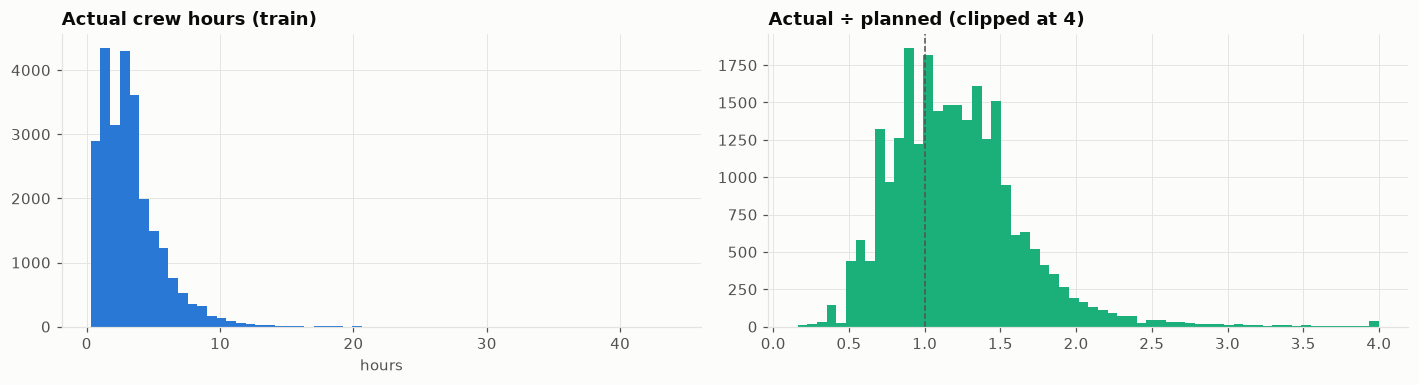

In [22]:
print(f"train {len(L_tr):,} | eval {len(L_ev):,} repaired defects")
display(L_tr[["actual_crew_hours", "planned_crew_hours", "crew_size"]].describe().T.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].hist(L_tr["actual_crew_hours"], bins=60, color=PALETTE[0])
axes[0].set_title("Actual crew hours (train)"); axes[0].set_xlabel("hours")
ratio = (L_tr["actual_crew_hours"] / L_tr["planned_crew_hours"]).dropna()
axes[1].hist(ratio.clip(0, 4), bins=60, color=PALETTE[2])
axes[1].axvline(1, color=INK2, ls="--", lw=1); axes[1].set_title("Actual ÷ planned (clipped at 4)")
fig.tight_layout(); save(fig, "08_hours_distribution")

### 8.1 How good is the plan? (baseline)

train: planned-as-prediction  R² = 0.550  MAE = 0.97 h  | median ratio 1.16
eval: planned-as-prediction  R² = 0.557  MAE = 0.95 h  | median ratio 1.14


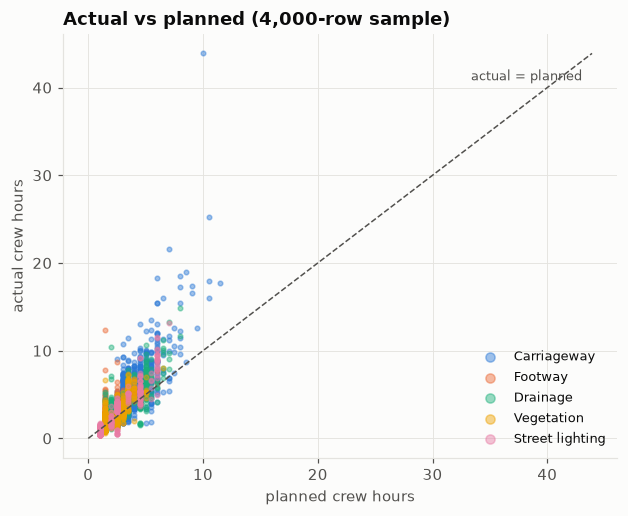

In [23]:
from sklearn.metrics import r2_score, mean_absolute_error
for name, df in [("train", L_tr), ("eval", L_ev)]:
    d = df.dropna(subset=["planned_crew_hours"])
    print(f"{name}: planned-as-prediction  R² = {r2_score(d.actual_crew_hours, d.planned_crew_hours):.3f}  "
          f"MAE = {mean_absolute_error(d.actual_crew_hours, d.planned_crew_hours):.2f} h  "
          f"| median ratio {np.median(d.actual_crew_hours / d.planned_crew_hours):.2f}")
fig, ax = plt.subplots(figsize=(6.5, 5))
smp = L_tr.dropna(subset=["planned_crew_hours"]).sample(4000, random_state=0)
for i, dtp in enumerate(DEFECT_ORDER):
    s = smp[smp["defect_type"] == dtp]
    ax.scatter(s["planned_crew_hours"], s["actual_crew_hours"], s=9, alpha=0.45, color=DEFECT_COLOR[dtp], label=dtp)
lim = [0, max(smp["planned_crew_hours"].max(), smp["actual_crew_hours"].max())]
ax.plot(lim, lim, color=INK2, lw=1, ls="--"); ax.text(lim[1] * 0.98, lim[1] * 0.93, "actual = planned", ha="right", color=INK2, fontsize=8.5)
ax.set_xlabel("planned crew hours"); ax.set_ylabel("actual crew hours"); ax.legend(fontsize=8.5, markerscale=2)
ax.set_title("Actual vs planned (4,000-row sample)")
save(fig, "08_actual_vs_planned")

### 8.2 What moves the overrun?

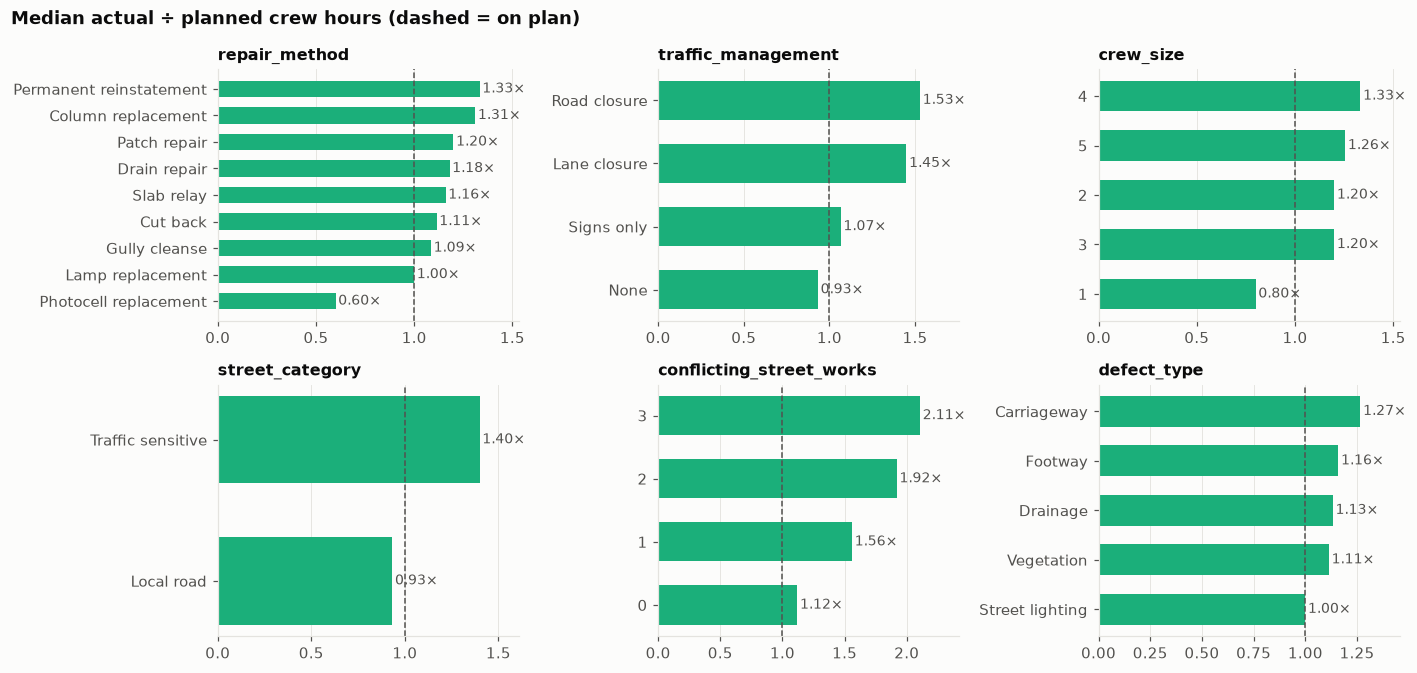

ratio,"(0.0, 0.9]","(0.9, 1.1]","(1.1, 1.5]","(1.5, 100.0]"
completion_code,,,,
Completed,0.43,0.29,0.28,0.00
Completed after return visit,0.00,0.00,0.00,1.00
Completed with overrun,0.00,0.00,0.59,0.41


In [24]:
L_tr["ratio"] = L_tr["actual_crew_hours"] / L_tr["planned_crew_hours"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.2))
for ax, col in zip(axes.flat, ["repair_method", "traffic_management", "crew_size", "street_category",
                               "conflicting_street_works", "defect_type"]):
    t = L_tr.groupby(col)["ratio"].median().dropna().sort_values(ascending=False)
    hbar(ax, t, PALETTE[2], fmt="{:.2f}×"); ax.set_title(col, fontsize=10.5)
    ax.axvline(1, color=INK2, lw=1, ls="--")
fig.suptitle("Median actual ÷ planned crew hours (dashed = on plan)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "08_ratio_drivers")
display(pd.crosstab(L_tr["completion_code"], pd.cut(L_tr["ratio"], [0, .9, 1.1, 1.5, 100]), normalize="index").round(2))

`completion_code` lines up with the overrun ratio ("Completed with overrun" falls in the high-ratio bins), which confirms that it is a post-outcome label and must not be a feature. The ratio charts point to the operational drivers the model can legitimately use: repair method, traffic management, crew size and conflicting street works.

## 9. Statement sentences — the NLP data

**Unit:** one sentence from a document attached to an older report. **Target:** `sentence_type`, which takes one of nine values. The model is TF-IDF + logistic regression, scored by macro-F1. The spec also requires that every class is predicted and that each class reaches ≥ 75% per-class recall.

### 9.1 Class balance, length and the stale length column

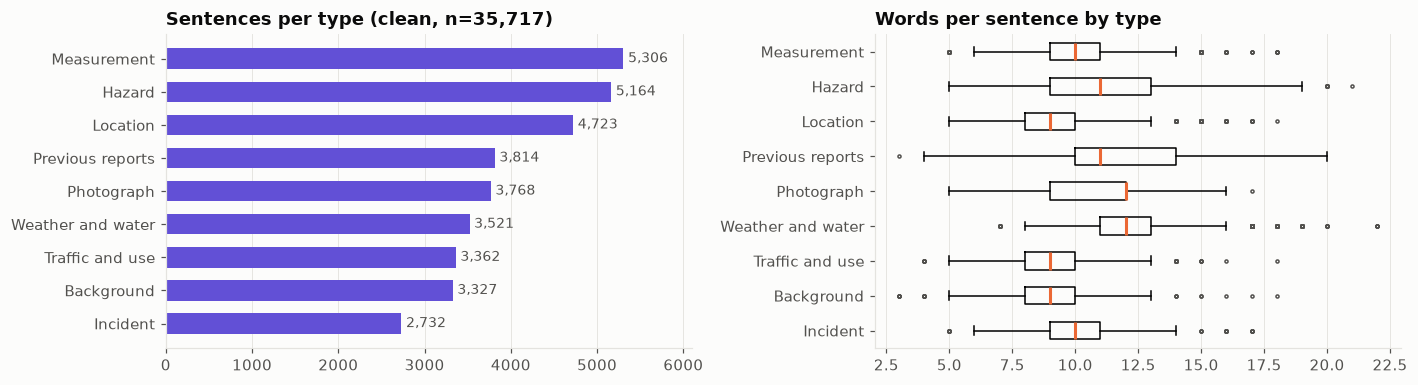

sentence_length_characters differs from the cleaned text length on 6,060 rows (16.7%) -> recompute it


sentence_type,Background,Hazard,Incident,Location,Measurement,Photograph,Previous reports,Traffic and use,Weather and water
document_type,,,,,,,,,
Call note,476,871,565,1038,533,9,617,521,471
Inspection note,219,569,11,519,823,10,1121,254,402
Photo note,0,0,0,86,1197,3379,0,0,0
Resident description,2632,3724,2156,3080,2753,370,2076,2587,2648


In [25]:
cls = S_clean["sentence_type"].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
hbar(axes[0], cls, PALETTE[6]); axes[0].set_title(f"Sentences per type (clean, n={len(S_clean):,})")
order = cls.index.tolist()
axes[1].boxplot([S_clean.loc[S_clean["sentence_type"] == t, "words"] for t in order], orientation="horizontal",
                tick_labels=order, widths=0.5, flierprops=dict(markersize=2, markeredgecolor=INK2),
                medianprops=dict(color=PALETTE[1], lw=2))
axes[1].set_title("Words per sentence by type"); axes[1].invert_yaxis(); axes[1].grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "09_sentence_classes")
stale = (S["raw_length"] != S["sentence_length_characters"])
print(f"sentence_length_characters differs from the cleaned text length on {stale.sum():,} rows ({stale.mean():.1%}) -> recompute it")
display(pd.crosstab(S_clean["document_type"], S_clean["sentence_type"]))

### 9.2 The most distinctive words per type

In [26]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import chi2
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True)
X = vec.fit_transform(S_clean["sentence_text"]); vocab = np.array(vec.get_feature_names_out())
rows = {}
for t in order:
    sc, _ = chi2(X, S_clean["sentence_type"] == t)
    rows[t] = ", ".join(vocab[np.argsort(sc)[::-1][:8]])
display(pd.Series(rows, name="top χ² terms").to_frame())

,top χ² terms
Measurement,"mm, wide, mm wide, deep, mm deep, ruler, shows it, the ruler"
Hazard,"anyone, to anyone, could, could easily, easily, it could, walking, easily cause"
Location,"number, it is, next to, is next, next, near, is on, box"
Previous reports,"has been, has, been, repaired, this, location on, this location, been repaired"
Photograph,"shows the, shows, picture, picture shows, whole width, the whole, whole, photo"
Weather and water,"rain, gets, rain water, onto, rain gets, after rain, rains, it rains"
Traffic and use,"use, busy, used, traffic, along, busy with, lot of, residents"
Background,"me, we run, run small, run, to me, mentioned, have mentioned, mentioned it"
Incident,"fell, fell on, and needed, needed, was hurt, tripped, man, hurt"


### 9.3 Learnability check (not the final model)

This is a quick stratified 80/20 split with the configuration the spec describes. The aim is only to confirm that the classes are separable from text alone; it is not the model that will be saved.

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report
Xtr, Xte, ytr, yte = train_test_split(S_clean["sentence_text"], S_clean["sentence_type"], test_size=0.2,
                                      stratify=S_clean["sentence_type"], random_state=42)
pipe = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
                 ("model", LogisticRegression(max_iter=2000))]).fit(Xtr, ytr)
pred = pipe.predict(Xte)
print(f"held-out macro-F1 = {f1_score(yte, pred, average='macro'):.3f}")
print(classification_report(yte, pred, digits=3))

held-out macro-F1 = 0.980
                   precision    recall  f1-score   support

       Background      0.988     0.982     0.985       665
           Hazard      0.982     0.949     0.965      1033
         Incident      0.974     0.980     0.977       546
         Location      0.968     0.970     0.969       945
      Measurement      0.972     0.992     0.982      1061
       Photograph      0.969     0.980     0.974       754
 Previous reports      0.995     0.984     0.989       763
  Traffic and use      0.975     0.984     0.979       673
Weather and water      0.992     1.000     0.996       704

         accuracy                          0.979      7144
        macro avg      0.979     0.980     0.980      7144
     weighted avg      0.979     0.979     0.979      7144



### 9.4 Measurement sentences carry figures

Only sentences typed *Measurement* are searched for figures, which are then compared with the report's own reading. Every disagreement is flagged for the inspector and never changes the report.

In [28]:
meas = S_clean[S_clean["sentence_type"] == "Measurement"]["sentence_text"]
pat = r"(\d+(?:\.\d+)?)\s*(mm|cm|m|in|inches|ft|feet)\b"
has = meas.str.contains(pat, case=False)
print(f"Measurement sentences with a figure + unit: {has.mean():.0%}")
print(meas.str.extract(pat, flags=re.I)[1].str.lower().value_counts().to_string())
print("\nExamples:\n" + meas.sample(5, random_state=1).to_string())

Measurement sentences with a figure + unit: 96%
1
mm        3520
m          948
inches     374
cm         192
feet        79

Examples:
31571                 The gully was surcharged to 91 mm.
25345    The ruler in the photo shows it is 570 mm wide.
20906      My phone level reads 6 degrees on the column.
25184         The caller says it is about 2 inches deep.
27899                 The pothole is 247 mm wide across.


## 10. Live inputs — the queue the system reviews

**40 open reports** (from 45 raw rows) · **60 documents** · **28 permits** (23 live)

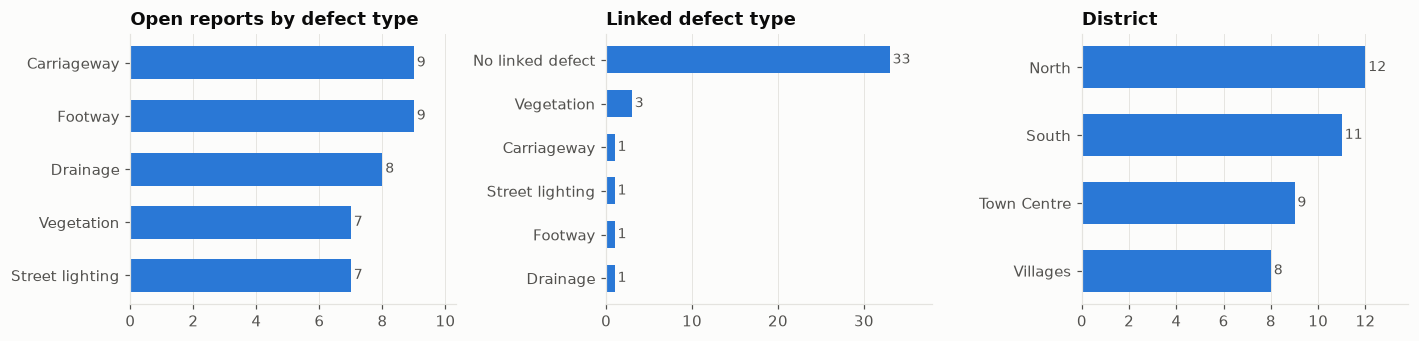

open reports on a street with ≥1 live permit: 19 of 40
open reports on a traffic-sensitive (or blank) street: 10


,report_reference,street_name,defect_type,linked_defect_type,street_category,Carriageway,Footway,live permits on street
0,SC0052197,Park Avenue,Drainage,Carriageway,Traffic sensitive,0.0,1.0,1.0
14,SC0052141,Albert Street,Footway,No linked defect,Local road,1.0,0.0,1.0
37,SC0052109,Southfield Road,Footway,No linked defect,Local road,1.0,0.0,1.0
31,SC0052169,Church Street,Footway,No linked defect,Local road,0.0,1.0,1.0
30,SC0052186,Mill Lane,Carriageway,Drainage,Local road,1.0,0.0,1.0
29,SC0052125,Market Place,Footway,No linked defect,Traffic sensitive,1.0,0.0,1.0
25,SC0052122,Grange Road,Carriageway,No linked defect,Local road,0.0,1.0,1.0
24,SC0052139,Hillside Road,Carriageway,No linked defect,NaN,0.0,1.0,1.0
23,SC0052161,Northgate,Street lighting,No linked defect,Traffic sensitive,1.0,0.0,1.0
1,SC0052163,Top Road,Carriageway,No linked defect,Local road,1.0,0.0,1.0


In [29]:
display(Markdown(f"**{len(OPEN)} open reports** (from {len(raw['open_defect_reports'])} raw rows) · "
                 f"**{len(DOCS)} documents** · **{len(REG)} permits** ({(REG.permit_status=='Live').sum()} live)"))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
hbar(axes[0], OPEN["defect_type"].value_counts().reindex(DEFECT_ORDER).fillna(0), PALETTE[0]); axes[0].set_title("Open reports by defect type")
hbar(axes[1], OPEN["linked_defect_type"].value_counts(), PALETTE[0]); axes[1].set_title("Linked defect type")
hbar(axes[2], OPEN["district"].value_counts(), PALETTE[0]); axes[2].set_title("District")
fig.tight_layout(); save(fig, "10_open_reports")

live = REG[REG["permit_status"] == "Live"]
works = live.groupby(["street_name", "works_location"]).size().unstack(fill_value=0)
q = OPEN[["report_reference", "street_name", "defect_type", "linked_defect_type", "street_category"]].merge(
    works, left_on="street_name", right_index=True, how="left").fillna({"Carriageway": 0, "Footway": 0})
q["live permits on street"] = q["Carriageway"] + q["Footway"]
print(f"open reports on a street with ≥1 live permit: {(q['live permits on street'] > 0).sum()} of {len(q)}")
print(f"open reports on a traffic-sensitive (or blank) street: {(q['street_category'] != 'Local road').sum()}")
display(q.sort_values("live permits on street", ascending=False).head(12))

### 10.1 Report documents

In [30]:
DOCS["words"] = DOCS["document_text"].str.split().str.len()
display(DOCS.groupby("document_type")["words"].describe().round(1))
per_report = DOCS.groupby("report_reference").size()
chk = OPEN.set_index("report_reference")["supporting_document_count"].astype(float).sub(per_report, fill_value=0)
print("reports whose supporting_document_count ≠ documents actually attached:", int((chk != 0).sum()))
print("example document:\n", DOCS["document_text"].iloc[0])

,count,mean,std,min,25%,50%,75%,max
document_type,,,,,,,,
Call note,13.0,39.8,10.9,24.0,30.0,40.0,48.0,56.0
Photo note,20.0,20.4,9.4,7.0,11.8,23.0,25.0,38.0
Resident description,27.0,46.8,13.5,20.0,37.0,48.0,55.0,72.0


reports whose supporting_document_count ≠ documents actually attached: 0
example document:
 It is on the south side of Long Lane. There is only 5.1 m clear above the road. Children walk along Long Lane to the primary school. The hedge on Long Lane was cut back but it has grown out again. Just to say, buses use Long Lane from early on. A previous repair here has worn away. It is outside number 133.


## 11. The 16 documents

The PDFs are the **only** source of requirements, figures, rules and checks. Nothing about them is hard-coded. Every document opens with `WRENFORD BOROUGH COUNCIL`, its title and one header line, and is then divided into numbered sections.

In [31]:
import pymupdf
docs = {}
for p in sorted((DATA / "docs").glob("*.pdf")):
    d = pymupdf.open(p); docs[p.stem] = "".join(pg.get_text() for pg in d)
sec_re = re.compile(r"^(\d+)\. (.+)$", re.M)
meta = pd.DataFrame([{"document": k, "words": len(t.split()), "sections": len(sec_re.findall(t)),
                      "header line": t.splitlines()[2][:90]} for k, t in docs.items()]).set_index("document")
display(meta)

,words,sections,header line
document,,,
Defect-Standard-Carriageway,1379,9,Document Standard 01 | Issue 6 | Owner: Highways Asset Management | Review c...
Defect-Standard-Drainage,1340,9,Document Standard 03 | Issue 4 | Owner: Highways Asset Management | Review c...
Defect-Standard-Footway,1374,9,Document Standard 02 | Issue 6 | Owner: Highways Asset Management | Review c...
Defect-Standard-Street-Lighting,1257,9,Document Standard 05 | Issue 5 | Owner: Highways Asset Management | Review c...
Defect-Standard-Vegetation,1314,9,Document Standard 04 | Issue 3 | Owner: Highways Asset Management | Review c...
Guide-Hazard,459,7,Document Guide 04 | Issue 3 | Owner: Street Care Office | Review cycle: ever...
Guide-Incident,445,7,Document Guide 05 | Issue 2 | Owner: Street Care Office | Review cycle: ever...
Guide-Location,539,7,Document Guide 02 | Issue 3 | Owner: Street Care Office | Review cycle: ever...
Guide-Measurement,578,7,Document Guide 01 | Issue 3 | Owner: Street Care Office | Review cycle: ever...


### 11.1 Requirements read out of each defect standard (section 4)

In [32]:
def requirements(text):
    s4 = re.search(r"^4\. Requirements\n(.*?)^5\. ", text, re.S | re.M).group(1)
    items = re.findall(r"^(\d+)\n(.+?)(?=^\d+\n|\Z)", s4, re.S | re.M)
    out = []
    for n, body in items:
        body = " ".join(body.split())
        name, _, sentence = body.partition(". ")
        if "never met by a sentence" in sentence: sentence = sentence.split(" A requirement is never")[0]
        out.append({"#": int(n), "requirement": name, "sentence": sentence,
                    "figures": ", ".join(re.findall(r"\d+(?:\.\d+)?\s*(?:millimetres|metres|degrees)", sentence))})
    return out
req = pd.concat({k.replace("Defect-Standard-", ""): pd.DataFrame(requirements(t))
                 for k, t in docs.items() if k.startswith("Defect-Standard")})
display(req)

#     requirement                                                                         sentence                            figures
Carriageway     0  1  Location fixed  The location of the defect is fixed to a house number, a lamp column number ...                                   
                1  2      Photograph                            A photograph of the defect is attached to the report.                                   
                2  3           Depth            The defect has a depth or a vertical step of at least 40 millimetres.                     40 millimetres
                3  4           Width  The defect measures at least 150 millimetres and at most 1500 millimetres ac...  150 millimetres, 1500 millimetres
Drainage        0  1  Location fixed  The location of the defect is fixed to a house number, a lamp column number ...                                   
                1  2      Photograph                            A photograph of the defect is attached to the report.                                   
                2  3     Water depth                              The standing water is at least 50 millimetres deep.                     50 millimetres
                3  4     Water reach  Where the water stands on the carriageway, it reaches at least 1.0 metres ou...                         1.0 metres
Footway         0  1  Location fixed  The location of the defect is fixed to a house number, a lamp column number ...                                   
                1  2      Photograph                            A photograph of the defect is attached to the report.                                   
                2  3           Depth            The defect has a depth or a vertical step of at least 20 millimetres.                     20 millimetres
                3  4           Width  The defect measures at least 150 millimetres and at most 1500 millimetres ac...  150 millimetres, 1500 millimetres
Street-Lighting 0  1  Location fixed  The location of the defect is fixed to a house number, a lamp column number ...                                   
                1  2   Column number                                   The lamp column number is given on the report.                                   
                2  3     Column lean              Where the column leans, it leans at least 5.0 degrees from upright.                        5.0 degrees
Vegetation      0  1  Location fixed  The location of the defect is fixed to a house number, a lamp column number ...                                   
                1  2    Highway land                                         The tree or hedge grows on highway land.                                   
                2  3    Clear height  The clear height under the overhang is less than 2.4 metres over a footway, ...             2.4 metres, 5.1 metres

The Carriageway and Footway standards use **identical wording** for Depth and Width but set **different figures**. A requirement must therefore be read from the report's *own* standard. A pipeline that picked up "the Depth requirement" from the wrong document would pass or fail the wrong reports.

### 11.2 Applying the parsed requirements to the history (illustration)

Screening the cleaned history with the *Depth* and *Width* figures parsed above gives a first look at the requirement-count features the repeat model will receive. (The full screening also covers yes/no requirements, water reach, clear height and lean, plus the linked standard.)

In [33]:
def fig_of(std, name):
    row = req.loc[std]; row = row[row["requirement"] == name]
    return [float(x) for x in re.findall(r"(\d+(?:\.\d+)?)", row["sentence"].iloc[0])] if len(row) else None
res = []
for std in ["Carriageway", "Footway"]:
    dmin = fig_of(std, "Depth")[0]; wmin, wmax = fig_of(std, "Width")[:2]
    sub = H_tr[H_tr["defect_type"] == std]
    depth = np.select([sub.defect_depth_mm.isna(), sub.defect_depth_mm >= dmin], ["Not documented", "Met"], "Not met")
    width = np.select([sub.defect_width_mm.isna(), sub.defect_width_mm.between(wmin, wmax)], ["Not documented", "Met"], "Not met")
    for nm, r in [(f"Depth ≥ {dmin:g} mm", depth), (f"Width {wmin:g}–{wmax:g} mm", width)]:
        ser = pd.Series(r)
        for outcome in ["Met", "Not met", "Not documented"]:
            m = ser.values == outcome
            res.append({"standard": std, "requirement": nm, "result": outcome, "reports": int(m.sum()),
                        "repeat rate": (sub["reported_again"].values[m] == "Yes").mean() if m.any() else np.nan})
display(pd.DataFrame(res).pivot_table(index=["standard", "requirement"], columns="result",
                                      values=["reports", "repeat rate"]).round(3))

repeat rate                        reports                       
result                                Met Not documented Not met     Met Not documented Not met
standard    requirement                                                                        
Carriageway Depth ≥ 40 mm           0.227          0.241   0.280  6746.0          477.0  1593.0
            Width 150–1500 mm       0.236          0.226   0.270  7810.0          584.0   422.0
Footway     Depth ≥ 20 mm           0.053          0.066   0.102  4990.0          350.0   983.0
            Width 150–1500 mm       0.061          0.051   0.087  5647.0          413.0   263.0

## 12. Cross-file checks and train/eval drift

history ∩ repair logs: 31,644 references (99% of logs)
history ∩ sentences:   0 references (0% of sentence reports)
train ∩ eval (history): 0  | train ∩ eval (logs): 0
live queue overlaps history: 0 | overlaps logs: 0


,train vs eval total-variation distance
defect_type,0.009
linked_defect_type,0.005
district,0.018
street_category,0.006
report_channel,0.005
reporter_type,0.004
reported_again,0.001
review_outcome,0.010
defect_type,0.010
repair_method,0.019


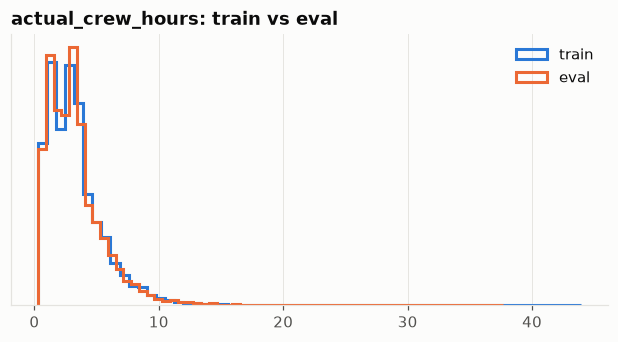

In [34]:
ref_h = set(H_tr.report_reference) | set(H_ev.report_reference)
ref_l = set(L_tr.report_reference) | set(L_ev.report_reference)
ref_s = set(S_clean.report_reference)
print(f"history ∩ repair logs: {len(ref_h & ref_l):,} references ({len(ref_h & ref_l)/len(ref_l):.0%} of logs)")
print(f"history ∩ sentences:   {len(ref_h & ref_s):,} references ({len(ref_h & ref_s)/len(ref_s):.0%} of sentence reports)")
print(f"train ∩ eval (history): {len(set(H_tr.report_reference) & set(H_ev.report_reference))}  "
      f"| train ∩ eval (logs): {len(set(L_tr.report_reference) & set(L_ev.report_reference))}")
open_refs = set(OPEN.report_reference)
print(f"live queue overlaps history: {len(open_refs & ref_h)} | overlaps logs: {len(open_refs & ref_l)}")

def drift(a, b, col):
    pa, pb = a[col].value_counts(normalize=True), b[col].value_counts(normalize=True)
    return float(0.5 * pa.subtract(pb, fill_value=0).abs().sum())  # total-variation distance
tv = pd.Series({c: drift(H_tr, H_ev, c) for c in ["defect_type", "linked_defect_type", "district",
                                                    "street_category", "report_channel", "reporter_type",
                                                    "reported_again", "review_outcome"]}, name="TV distance (history)")
tv2 = pd.Series({c: drift(L_tr, L_ev, c) for c in ["defect_type", "repair_method", "traffic_management",
                                                     "crew_size", "completion_code"]}, name="TV distance (logs)")
display(pd.concat([tv, tv2]).round(3).to_frame("train vs eval total-variation distance"))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(L_tr["actual_crew_hours"], bins=60, density=True, histtype="step", lw=2, color=PALETTE[0], label="train")
ax.hist(L_ev["actual_crew_hours"], bins=60, density=True, histtype="step", lw=2, color=PALETTE[1], label="eval")
ax.legend(); ax.set_title("actual_crew_hours: train vs eval"); ax.set_yticks([])
save(fig, "12_drift_hours")

A total-variation distance close to 0 means the held-out file is drawn from the same population as the training file, so held-out scores are fair estimates. There is **no reference overlap between train and eval**, so no report leaks across the split.

## 13. Findings and implications

The numbers quoted below are computed live by the next cell.

In [35]:
f = {}
f["hist_raw"], f["hist_clean"] = len(raw["report_history_train"]), len(H_tr)
f["rate_tr"], f["rate_ev"] = y_tr.mean(), y_ev.mean()
f["logs_clean"] = len(L_tr)
d = L_ev.dropna(subset=["planned_crew_hours"])
f["plan_r2"] = r2_score(d.actual_crew_hours, d.planned_crew_hours)
f["plan_mae"] = mean_absolute_error(d.actual_crew_hours, d.planned_crew_hours)
f["sent_clean"], f["f1"] = len(S_clean), f1_score(yte, pred, average="macro")
f["small_groups"] = (grp < 5).mean()
display(Markdown(f"""
**Data quality**
1. Every file contains exact duplicate rows, and all eight need dedup before anything else.
2. Six spellings of *missing* (`N/A`, `not known`, `null`, `caller unsure`, `-`, empty) appear across all files. `None` is a real value, not a null.
3. Each channel writes references in its own notation and has its own unit habits (mm/cm/in, m/ft, min/hr/hrs). Every value is parsed from its own suffix, with exact-decimal, round-half-up conversion.
4. Categories carry case/padding noise **and** channel vocabulary (`FW` = `Pavement defect` = `Footway`). The mappings must be closed, and any unknown spelling refused.
5. Revisions are scattered through the history. Keeping the highest `revision_number` reduces {f['hist_raw']:,} raw rows to **{f['hist_clean']:,}** trainable reports.
6. Impossible readings exist (negative depths, zero widths and heights, lean > 90°, negative counts and hours). They are blanked, never corrected.
7. Sentences carry markup, entities, U+00A0, padding, all-caps text and too-short fragments, and the stored length column is stale.
8. The cleaned live files give exactly the counts in the spec (40 reports, 60 documents, 28 permits / 23 live), which validates the cleaning logic.

**Modelling implications**
* **Repeat model.** The target is imbalanced ({f['rate_tr']:.1%} train vs {f['rate_ev']:.1%} eval), so it should be scored by ROC AUC and its calibration checked. Most missing values are *structural* and depend on defect type, so imputation must carry a missing-indicator rather than invent readings. `review_outcome` and `repeat_cause` are post-outcome **leakage**.
* **Crew-hours model.** Planned hours alone reach R² = {f['plan_r2']:.2f} and MAE = {f['plan_mae']:.2f} h on eval, so this is the baseline to beat. Repair method, traffic management, crew size and conflicting works shift the actual-to-planned ratio. `completion_code` is leakage.
* **Sentence model.** A plain TF-IDF + logistic regression already reaches macro-F1 ≈ {f['f1']:.2f} on a held-out split of {f['sent_clean']:,} clean sentences, and each type has distinctive vocabulary.
* **Requirements.** These must be parsed from each defect type's own standard. Carriageway and Footway share wording but not figures.
* **Privacy line.** {f['small_groups']:.0%} of street × defect-type groups have fewer than 5 reports, so the chat must withhold those figures.
* Train and eval are disjoint by reference and closely matched in distribution, so held-out scores are trustworthy estimates.
"""))


**Data quality**
1. Every file contains exact duplicate rows, and all eight need dedup before anything else.
2. Six spellings of *missing* (`N/A`, `not known`, `null`, `caller unsure`, `-`, empty) appear across all files. `None` is a real value, not a null.
3. Each channel writes references in its own notation and has its own unit habits (mm/cm/in, m/ft, min/hr/hrs). Every value is parsed from its own suffix, with exact-decimal, round-half-up conversion.
4. Categories carry case/padding noise **and** channel vocabulary (`FW` = `Pavement defect` = `Footway`). The mappings must be closed, and any unknown spelling refused.
5. Revisions are scattered through the history. Keeping the highest `revision_number` reduces 32,738 raw rows to **30,569** trainable reports.
6. Impossible readings exist (negative depths, zero widths and heights, lean > 90°, negative counts and hours). They are blanked, never corrected.
7. Sentences carry markup, entities, U+00A0, padding, all-caps text and too-short fragments, and the stored length column is stale.
8. The cleaned live files give exactly the counts in the spec (40 reports, 60 documents, 28 permits / 23 live), which validates the cleaning logic.

**Modelling implications**
* **Repeat model.** The target is imbalanced (20.2% train vs 20.3% eval), so it should be scored by ROC AUC and its calibration checked. Most missing values are *structural* and depend on defect type, so imputation must carry a missing-indicator rather than invent readings. `review_outcome` and `repeat_cause` are post-outcome **leakage**.
* **Crew-hours model.** Planned hours alone reach R² = 0.56 and MAE = 0.95 h on eval, so this is the baseline to beat. Repair method, traffic management, crew size and conflicting works shift the actual-to-planned ratio. `completion_code` is leakage.
* **Sentence model.** A plain TF-IDF + logistic regression already reaches macro-F1 ≈ 0.98 on a held-out split of 35,717 clean sentences, and each type has distinctive vocabulary.
* **Requirements.** These must be parsed from each defect type's own standard. Carriageway and Footway share wording but not figures.
* **Privacy line.** 5% of street × defect-type groups have fewer than 5 reports, so the chat must withhold those figures.
* Train and eval are disjoint by reference and closely matched in distribution, so held-out scores are trustworthy estimates.
